# 03. Unsupervised Mining: Market Basket Analysis and Customer Segmentation

**Stage 3 of the pipeline: discover which products sell together and which customer groups behave alike.**

| | |
|---|---|
| **Project** | Online Retail II: Data Warehouse and Data Mining |
| **Author** | Sara Mohammad Zreigat |
| **Dataset** | UCI Online Retail II (cleaned), December 2009 to December 2011 |

### Objectives

1. Mine frequent itemsets and association rules with the Apriori algorithm.
2. Translate the strongest rules into cross-selling recommendations.
3. Engineer Recency, Frequency and Monetary (RFM) features for every customer.
4. Select the number of clusters objectively and segment customers with K-Means.
5. Profile each segment and define a targeted marketing action.

## 1. Environment setup

Put this notebook and **Online_Retail_II_Cleaned.csv** in the same folder (or, on Google Colab, run the cells and upload
the CSV when asked). The first code cell installs the two libraries Colab may be missing, the second holds the project's
helper functions, and the third loads the data.

In [ ]:
%pip install -q mlxtend duckdb

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [3]:
# @title Project helper library (run this cell first)
# All reusable functions of the project in one place so this notebook runs on its own.
# Author: Sara Mohammad Zreigat

from types import SimpleNamespace
import logging


# ============================================================================
# Module: config
# ============================================================================

"""Project-wide configuration: paths, constants and analysis parameters."""


from pathlib import Path

# ---------------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------------
PROJECT_ROOT = Path.cwd()

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

PROCESSED_DATASET = PROJECT_ROOT / "Online_Retail_II_Cleaned.csv"
RAW_DATASET = RAW_DATA_DIR / "online_retail_II.xlsx"

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
WAREHOUSE_DIR = ARTIFACTS_DIR / "warehouse"
WAREHOUSE_DB = WAREHOUSE_DIR / "retail_dw.duckdb"
FIGURES_DIR = PROJECT_ROOT / "figures"
SQL_DIR = PROJECT_ROOT / "sql"

# ---------------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------------
RANDOM_STATE = 42

# ---------------------------------------------------------------------------
# Domain constants
# ---------------------------------------------------------------------------
# Stock codes that represent fees, postage, adjustments or test entries rather
# than merchandise. They are kept in revenue totals but excluded from
# product-level analysis (rankings, market basket analysis).
NON_MERCHANDISE_CODES: frozenset[str] = frozenset(
    {
        "POST",
        "DOT",
        "M",
        "C2",
        "ADJUST",
        "ADJUST2",
        "BANK CHARGES",
        "PADS",
        "D",
        "TEST001",
        "TEST002",
        "AMAZONFEE",
        "CRUK",
        "S",
        "B",
    }
)

RAW_SHEETS: tuple[str, ...] = ("Year 2009-2010", "Year 2010-2011")

RAW_COLUMN_MAP: dict[str, str] = {
    "Invoice": "InvoiceNo",
    "Price": "UnitPrice",
    "Customer ID": "CustomerID",
}

CLEAN_COLUMNS: list[str] = [
    "InvoiceNo",
    "StockCode",
    "Description",
    "Quantity",
    "InvoiceDate",
    "DateKey",
    "Year",
    "Month",
    "Day",
    "Quarter",
    "Hour",
    "UnitPrice",
    "TotalAmount",
    "CustomerID",
    "Country",
]

# ---------------------------------------------------------------------------
# Analysis parameters
# ---------------------------------------------------------------------------
BASKET_COUNTRY = "United Kingdom"
APRIORI_MIN_SUPPORT = 0.01
RULES_MIN_CONFIDENCE = 0.30
RULES_MIN_LIFT = 1.0

KMEANS_K_RANGE = range(2, 9)
KMEANS_MIN_K = 3  # smallest number of segments that is actionable for marketing

TEST_MONTH_SHARE = 0.20

# ---------------------------------------------------------------------------
# Visual identity (shared by notebooks and dashboard)
# ---------------------------------------------------------------------------
PALETTE = {
    "primary": "#1F3A5F",
    "secondary": "#3D7EA6",
    "accent": "#C8963E",
    "positive": "#2E8B57",
    "negative": "#B23A48",
    "neutral": "#8A94A6",
    "background": "#F6F8FB",
    "ink": "#1B2430",
}

SEGMENT_COLORS = {
    "Champions": "#1F3A5F",
    "Promising": "#3D7EA6",
    "At Risk": "#C8963E",
    "Hibernating": "#8A94A6",
}

CATEGORICAL_SEQUENCE = [
    "#1F3A5F",
    "#3D7EA6",
    "#C8963E",
    "#2E8B57",
    "#B23A48",
    "#6C5B7B",
    "#8A94A6",
]


def ensure_directories() -> None:
    """Create all output directories used by the pipeline."""
    for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, WAREHOUSE_DIR, FIGURES_DIR):
        directory.mkdir(parents=True, exist_ok=True)

config = SimpleNamespace(PROJECT_ROOT=PROJECT_ROOT, DATA_DIR=DATA_DIR, RAW_DATA_DIR=RAW_DATA_DIR, PROCESSED_DATA_DIR=PROCESSED_DATA_DIR, PROCESSED_DATASET=PROCESSED_DATASET, RAW_DATASET=RAW_DATASET, ARTIFACTS_DIR=ARTIFACTS_DIR, WAREHOUSE_DIR=WAREHOUSE_DIR, WAREHOUSE_DB=WAREHOUSE_DB, FIGURES_DIR=FIGURES_DIR, SQL_DIR=SQL_DIR, RANDOM_STATE=RANDOM_STATE, NON_MERCHANDISE_CODES=NON_MERCHANDISE_CODES, RAW_SHEETS=RAW_SHEETS, RAW_COLUMN_MAP=RAW_COLUMN_MAP, CLEAN_COLUMNS=CLEAN_COLUMNS, BASKET_COUNTRY=BASKET_COUNTRY, APRIORI_MIN_SUPPORT=APRIORI_MIN_SUPPORT, RULES_MIN_CONFIDENCE=RULES_MIN_CONFIDENCE, RULES_MIN_LIFT=RULES_MIN_LIFT, KMEANS_K_RANGE=KMEANS_K_RANGE, KMEANS_MIN_K=KMEANS_MIN_K, TEST_MONTH_SHARE=TEST_MONTH_SHARE, PALETTE=PALETTE, SEGMENT_COLORS=SEGMENT_COLORS, CATEGORICAL_SEQUENCE=CATEGORICAL_SEQUENCE, ensure_directories=ensure_directories)


# ============================================================================
# Module: data
# ============================================================================

"""Data access, cleaning (ETL) and data-quality validation.

The repository ships the cleaned transactional dataset in
``data/processed/online_retail_ii_cleaned.parquet``. The full cleaning logic
that produced it from the raw UCI workbook is implemented in
:func:`clean_raw_transactions` so that the processed file can be regenerated
from source at any time (see ``scripts/run_pipeline.py --from-raw``).
"""


from pathlib import Path

import numpy as np
import pandas as pd


# ---------------------------------------------------------------------------
# Loading
# ---------------------------------------------------------------------------

_DTYPES = {
    "InvoiceNo": "string",
    "StockCode": "string",
    "Description": "string",
    "Country": "string",
}


def _standardise_types(df: pd.DataFrame) -> pd.DataFrame:
    """Apply the canonical dtypes used throughout the project."""
    df = df.copy()
    for column, dtype in _DTYPES.items():
        if column in df.columns:
            df[column] = df[column].astype(dtype)
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    df["CustomerID"] = df["CustomerID"].astype("int64")
    for column in ("Quantity", "DateKey", "Year", "Month", "Day", "Quarter", "Hour"):
        if column in df.columns:
            df[column] = df[column].astype("int64")
    for column in ("UnitPrice", "TotalAmount"):
        df[column] = df[column].astype("float64")
    return df


def load_transactions(path: str | Path | None = None) -> pd.DataFrame:
    """Load the cleaned transaction-level dataset.

    Parameters
    ----------
    path:
        Optional path to a ``.parquet`` or ``.csv`` file. Defaults to the
        processed dataset shipped with the repository.
    """
    path = Path(path) if path is not None else config.PROCESSED_DATASET
    if not path.exists():
        raise FileNotFoundError(
            f"Dataset not found at '{path}'. Make sure the repository data "
            "folder is present or run scripts/run_pipeline.py --from-raw."
        )
    if path.suffix == ".parquet":
        df = pd.read_parquet(path)
    else:
        df = pd.read_csv(path, dtype={k: "string" for k in _DTYPES})
    df = _standardise_types(df)
    return df[config.CLEAN_COLUMNS].sort_values(["InvoiceDate", "InvoiceNo"]).reset_index(drop=True)


def load_raw_workbook(path: str | Path | None = None) -> pd.DataFrame:
    """Read and concatenate both yearly sheets of the raw UCI workbook."""
    path = Path(path) if path is not None else config.RAW_DATASET
    if not path.exists():
        raise FileNotFoundError(
            f"Raw workbook not found at '{path}'. Download 'online_retail_II.xlsx' "
            "from https://archive.ics.uci.edu/dataset/502/online+retail+ii "
            "and place it in data/raw/."
        )
    frames = [pd.read_excel(path, sheet_name=sheet) for sheet in config.RAW_SHEETS]
    return pd.concat(frames, ignore_index=True)


# ---------------------------------------------------------------------------
# Cleaning (ETL transform step)
# ---------------------------------------------------------------------------


def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    """Derive calendar attributes used by the time dimension."""
    df = df.copy()
    dates = df["InvoiceDate"]
    df["DateKey"] = dates.dt.strftime("%Y%m%d").astype("int64")
    df["Year"] = dates.dt.year.astype("int64")
    df["Month"] = dates.dt.month.astype("int64")
    df["Day"] = dates.dt.day.astype("int64")
    df["Quarter"] = dates.dt.quarter.astype("int64")
    df["Hour"] = dates.dt.hour.astype("int64")
    return df


def clean_raw_transactions(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply the full cleaning procedure to raw Online Retail II records.

    Steps
    -----
    1. Standardise column names.
    2. Trim text fields and parse invoice timestamps.
    3. Drop records without a customer identifier or product description.
    4. Remove exact duplicate rows.
    5. Remove cancelled invoices (invoice numbers prefixed with ``C``).
    6. Keep only positive quantities and positive unit prices.
    7. Derive calendar features and the ``TotalAmount`` measure.

    Returns
    -------
    clean:
        The cleaned dataset with the canonical column order.
    audit:
        A step-by-step log of the number of rows removed by each rule.
    """
    log: list[dict[str, object]] = []

    def record(step: str, before: int, after: int) -> None:
        log.append({"Step": step, "RowsBefore": before, "RowsAfter": after, "RowsRemoved": before - after})

    df = raw.rename(columns=config.RAW_COLUMN_MAP).copy()
    record("Input records", len(df), len(df))

    df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
    df["StockCode"] = df["StockCode"].astype("string").str.strip().str.upper()
    df["Description"] = df["Description"].astype("string").str.strip()
    df["Country"] = df["Country"].astype("string").str.strip()
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

    before = len(df)
    df = df.dropna(subset=["CustomerID"])
    record("Drop missing CustomerID", before, len(df))

    before = len(df)
    df = df.dropna(subset=["Description"])
    df = df[df["Description"].str.len() > 0]
    record("Drop missing Description", before, len(df))

    before = len(df)
    df = df.drop_duplicates()
    record("Remove exact duplicates", before, len(df))

    before = len(df)
    df = df[~df["InvoiceNo"].str.startswith("C")]
    record("Remove cancelled invoices", before, len(df))

    before = len(df)
    df = df[df["Quantity"] > 0]
    record("Keep Quantity > 0", before, len(df))

    before = len(df)
    df = df[df["UnitPrice"] > 0]
    record("Keep UnitPrice > 0", before, len(df))

    before = len(df)
    df = df.dropna(subset=["InvoiceDate"])
    record("Drop invalid dates", before, len(df))

    df = add_time_features(df)
    df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]
    df = _standardise_types(df)
    df = df[config.CLEAN_COLUMNS].sort_values(["InvoiceDate", "InvoiceNo"]).reset_index(drop=True)

    return df, pd.DataFrame(log)


# ---------------------------------------------------------------------------
# Validation
# ---------------------------------------------------------------------------


def validate_transactions(df: pd.DataFrame) -> pd.DataFrame:
    """Run data-quality assertions and return a tabular report.

    Every rule enforced by :func:`clean_raw_transactions` is re-checked here,
    together with internal consistency checks on derived columns.
    """
    expected_total = df["Quantity"] * df["UnitPrice"]
    expected_datekey = df["InvoiceDate"].dt.strftime("%Y%m%d").astype("int64")

    checks = [
        ("Schema matches canonical column list", list(df.columns) == config.CLEAN_COLUMNS, 0),
        ("No missing values", True, int(df.isna().sum().sum())),
        ("No exact duplicate rows", True, int(df.duplicated().sum())),
        ("No cancelled invoices", True, int(df["InvoiceNo"].str.startswith("C").sum())),
        ("Quantity strictly positive", True, int((df["Quantity"] <= 0).sum())),
        ("UnitPrice strictly positive", True, int((df["UnitPrice"] <= 0).sum())),
        ("TotalAmount equals Quantity x UnitPrice", True, int((~np.isclose(df["TotalAmount"], expected_total, atol=0.01)).sum())),
        ("DateKey consistent with InvoiceDate", True, int((df["DateKey"] != expected_datekey).sum())),
        ("Year consistent with InvoiceDate", True, int((df["Year"] != df["InvoiceDate"].dt.year).sum())),
        ("Quarter consistent with Month", True, int((df["Quarter"] != (df["Month"] - 1) // 3 + 1).sum())),
    ]

    rows = []
    for name, structural_ok, violations in checks:
        passed = bool(structural_ok) and violations == 0
        rows.append({"Check": name, "Violations": violations, "Status": "PASS" if passed else "FAIL"})
    return pd.DataFrame(rows)


def dataset_profile(df: pd.DataFrame) -> pd.DataFrame:
    """High-level descriptive profile of the dataset."""
    metrics = {
        "Transaction lines": len(df),
        "Invoices": df["InvoiceNo"].nunique(),
        "Customers": df["CustomerID"].nunique(),
        "Products (stock codes)": df["StockCode"].nunique(),
        "Countries": df["Country"].nunique(),
        "First invoice": df["InvoiceDate"].min().strftime("%Y-%m-%d"),
        "Last invoice": df["InvoiceDate"].max().strftime("%Y-%m-%d"),
        "Total revenue (GBP)": f"{df['TotalAmount'].sum():,.2f}",
        "Total units sold": f"{df['Quantity'].sum():,}",
    }
    return pd.DataFrame({"Metric": list(metrics.keys()), "Value": [str(v) for v in metrics.values()]})


def merchandise_only(df: pd.DataFrame) -> pd.DataFrame:
    """Exclude fee, postage, adjustment and test stock codes."""
    return df[~df["StockCode"].isin(config.NON_MERCHANDISE_CODES)]

# ============================================================================
# Module: plotting
# ============================================================================

"""Consistent Matplotlib styling and figure export for notebooks and reports."""


from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


PALETTE = config.PALETTE


def set_style() -> None:
    """Apply the project-wide Matplotlib theme."""
    mpl.rcParams.update(
        {
            "figure.figsize": (10, 5.2),
            "figure.dpi": 110,
            "savefig.dpi": 160,
            "savefig.bbox": "tight",
            "figure.facecolor": "white",
            "axes.facecolor": "white",
            "axes.edgecolor": "#C9D1DC",
            "axes.linewidth": 0.8,
            "axes.grid": True,
            "axes.grid.axis": "y",
            "grid.color": "#E6EAF0",
            "grid.linewidth": 0.8,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "axes.titlesize": 13,
            "axes.titleweight": "bold",
            "axes.titlelocation": "left",
            "axes.titlepad": 12,
            "axes.labelsize": 10.5,
            "axes.labelcolor": PALETTE["ink"],
            "xtick.color": "#4A5568",
            "ytick.color": "#4A5568",
            "xtick.labelsize": 9.5,
            "ytick.labelsize": 9.5,
            "legend.frameon": False,
            "legend.fontsize": 9.5,
            "font.family": "DejaVu Sans",
            "axes.prop_cycle": mpl.cycler(color=config.CATEGORICAL_SEQUENCE),
        }
    )


def currency_formatter(prefix: str = "GBP ") -> FuncFormatter:
    """Compact currency tick labels (e.g. GBP 1.2M)."""

    def _fmt(value: float, _pos=None) -> str:
        magnitude = abs(value)
        if magnitude >= 1e6:
            return f"{prefix}{value / 1e6:.1f}M"
        if magnitude >= 1e3:
            return f"{prefix}{value / 1e3:.0f}K"
        return f"{prefix}{value:.0f}"

    return FuncFormatter(_fmt)


def thousands_formatter() -> FuncFormatter:
    return FuncFormatter(lambda value, _pos=None: f"{value / 1e3:.0f}K" if abs(value) >= 1e3 else f"{value:.0f}")


def save_figure(fig: plt.Figure, name: str, directory: Path | None = None) -> Path:
    """Save a figure as PNG into ``reports/figures``."""
    directory = directory or config.FIGURES_DIR
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / f"{name}.png"
    fig.savefig(path)
    return path


def star_schema_diagram(tables: dict[str, list[str]], keys: dict[str, dict[str, str]]) -> plt.Figure:
    """Draw an entity-relationship diagram of a star schema.

    Parameters
    ----------
    tables:
        Mapping of table name to its column list. The table whose name starts
        with ``fact`` is drawn in the centre.
    keys:
        Mapping of table name to ``{column: "PK" | "FK"}`` annotations.
    """
    from matplotlib.patches import FancyBboxPatch

    fact_name = next(name for name in tables if name.startswith("fact"))
    dims = [name for name in tables if name != fact_name]
    positions = {fact_name: (0.5, 0.5)}
    corners = [(0.14, 0.78), (0.86, 0.78), (0.14, 0.24), (0.86, 0.24)]
    for name, pos in zip(dims, corners):
        positions[name] = pos

    fig, ax = plt.subplots(figsize=(13, 8.2))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    row_h = 0.032
    width = 0.24
    boxes = {}
    for name, (cx, cy) in positions.items():
        columns = tables[name]
        height = row_h * (len(columns) + 1.4)
        x0, y0 = cx - width / 2, cy - height / 2
        is_fact = name == fact_name
        header_color = PALETTE["primary"] if is_fact else PALETTE["secondary"]
        ax.add_patch(FancyBboxPatch((x0, y0), width, height, boxstyle="round,pad=0.004,rounding_size=0.01",
                                    facecolor="white", edgecolor=header_color, linewidth=1.6, zorder=2))
        ax.add_patch(FancyBboxPatch((x0, y0 + height - row_h * 1.3), width, row_h * 1.3,
                                    boxstyle="round,pad=0.004,rounding_size=0.01", facecolor=header_color,
                                    edgecolor=header_color, linewidth=1.6, zorder=3))
        ax.text(cx, y0 + height - row_h * 0.65, name.upper(), ha="center", va="center", color="white",
                fontsize=10.5, fontweight="bold", zorder=4)
        for i, column in enumerate(columns):
            tag = keys.get(name, {}).get(column, "")
            y = y0 + height - row_h * (1.3 + i + 0.6)
            ax.text(x0 + 0.012, y, column, ha="left", va="center", fontsize=8.6, color=PALETTE["ink"], zorder=4,
                    fontweight="bold" if tag == "PK" else "normal")
            if tag:
                ax.text(x0 + width - 0.012, y, tag, ha="right", va="center", fontsize=7.6, zorder=4,
                        color=PALETTE["accent"] if tag == "PK" else PALETTE["secondary"])
        boxes[name] = (x0, y0, width, height)

    fx0, fy0, fw, fh = boxes[fact_name]
    for name in dims:
        x0, y0, w, h = boxes[name]
        cx, cy = positions[name]
        start_x = fx0 if cx < 0.5 else fx0 + fw
        end_x = x0 + w if cx < 0.5 else x0
        ax.annotate("", xy=(start_x, 0.5 + (0.08 if cy > 0.5 else -0.08)), xytext=(end_x, cy),
                    arrowprops=dict(arrowstyle="-|>", color=PALETTE["neutral"], linewidth=1.3,
                                    connectionstyle="arc3,rad=0.0"), zorder=1)
    ax.set_title("Star schema: one fact table at invoice-line grain, four conformed dimensions", loc="left")
    return fig


def pretty_label(text: str, width: int | None = None) -> str:
    """Title-case a product description without breaking apostrophes, optionally wrapping it."""
    import string
    import textwrap

    label = string.capwords(" ".join(str(text).lower().split()))
    return "\n".join(textwrap.wrap(label, width)) if width else label

# ============================================================================
# Module: artifacts
# ============================================================================

"""Locations and helpers for persisted pipeline outputs.

Small, version-controlled result tables live under ``artifacts/`` so that the
dashboard and the documentation can be rebuilt without re-running the models.
Large binaries (the DuckDB file and fitted models) are regenerated locally and
excluded from version control.
"""


import json
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd


QUALITY_DIR = config.ARTIFACTS_DIR / "quality"
WAREHOUSE_DIR = config.WAREHOUSE_DIR
SEGMENTATION_DIR = config.ARTIFACTS_DIR / "segmentation"
ASSOCIATION_DIR = config.ARTIFACTS_DIR / "association"
MODELING_DIR = config.ARTIFACTS_DIR / "modeling"
MODELS_DIR = config.ARTIFACTS_DIR / "models"

ALL_DIRS = (QUALITY_DIR, WAREHOUSE_DIR, SEGMENTATION_DIR, ASSOCIATION_DIR, MODELING_DIR, MODELS_DIR)


def ensure_dirs() -> None:
    config.ensure_directories()
    for directory in ALL_DIRS:
        directory.mkdir(parents=True, exist_ok=True)


class _Encoder(json.JSONEncoder):
    def default(self, obj: Any):  # noqa: D401 - JSON hook
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, (np.integer,)):
            return int(obj)
        if isinstance(obj, (np.floating,)):
            return float(obj)
        return super().default(obj)


def save_table(frame: pd.DataFrame, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.suffix == ".parquet":
        frame.to_parquet(path, index=False)
    else:
        frame.to_csv(path, index=False)
    return path


def load_table(path: Path) -> pd.DataFrame:
    return pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)


def save_json(payload: dict, path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, cls=_Encoder), encoding="utf-8")
    return path


def load_json(path: Path) -> dict:
    return json.loads(Path(path).read_text(encoding="utf-8"))

# ============================================================================
# Module: warehouse
# ============================================================================

SQL_FILES = {
    "schema.sql": """-- =============================================================================
-- Online Retail II - Star Schema (DuckDB dialect, ANSI-compatible)
-- Grain of the fact table: one row per invoice line.
-- Author: Sara Mohammad Zreigat
-- =============================================================================

-- -----------------------------------------------------------------------------
-- Dimension: calendar date (day grain)
-- -----------------------------------------------------------------------------
CREATE TABLE dim_date (
    DateKey        INTEGER      PRIMARY KEY,   -- YYYYMMDD smart key
    FullDate       DATE         NOT NULL,
    Year           SMALLINT     NOT NULL,
    Quarter        TINYINT      NOT NULL,
    Month          TINYINT      NOT NULL,
    MonthName      VARCHAR(12)  NOT NULL,
    YearMonth      VARCHAR(7)   NOT NULL,
    Day            TINYINT      NOT NULL,
    DayOfWeek      TINYINT      NOT NULL,      -- 1 = Monday ... 7 = Sunday
    DayName        VARCHAR(10)  NOT NULL,
    WeekOfYear     TINYINT      NOT NULL,
    IsWeekend      BOOLEAN      NOT NULL
);

-- -----------------------------------------------------------------------------
-- Dimension: customer
-- -----------------------------------------------------------------------------
CREATE TABLE dim_customer (
    CustomerKey        INTEGER      PRIMARY KEY,   -- surrogate key
    CustomerID         INTEGER      NOT NULL UNIQUE, -- natural key from source
    PrimaryCountry     VARCHAR(40)  NOT NULL,
    FirstPurchaseDate  DATE         NOT NULL,
    LastPurchaseDate   DATE         NOT NULL
);

-- -----------------------------------------------------------------------------
-- Dimension: product
-- -----------------------------------------------------------------------------
CREATE TABLE dim_product (
    ProductKey          INTEGER        PRIMARY KEY,  -- surrogate key
    StockCode           VARCHAR(20)    NOT NULL UNIQUE,
    Description         VARCHAR(100)   NOT NULL,
    ReferenceUnitPrice  DECIMAL(10, 2) NOT NULL,
    IsMerchandise       BOOLEAN        NOT NULL
);

-- -----------------------------------------------------------------------------
-- Dimension: location
-- -----------------------------------------------------------------------------
CREATE TABLE dim_location (
    LocationKey   INTEGER      PRIMARY KEY,      -- surrogate key
    Country       VARCHAR(40)  NOT NULL UNIQUE,  -- value as recorded in source
    CountryName   VARCHAR(40)  NOT NULL,         -- standardised display name
    ISO3          VARCHAR(3),
    Region        VARCHAR(30)  NOT NULL
);

-- -----------------------------------------------------------------------------
-- Fact: sales (invoice line grain)
-- -----------------------------------------------------------------------------
CREATE TABLE fact_sales (
    SalesKey      BIGINT          PRIMARY KEY,
    InvoiceNo     VARCHAR(10)     NOT NULL,      -- degenerate dimension
    DateKey       INTEGER         NOT NULL REFERENCES dim_date (DateKey),
    CustomerKey   INTEGER         NOT NULL REFERENCES dim_customer (CustomerKey),
    ProductKey    INTEGER         NOT NULL REFERENCES dim_product (ProductKey),
    LocationKey   INTEGER         NOT NULL REFERENCES dim_location (LocationKey),
    InvoiceHour   TINYINT         NOT NULL,
    Quantity      INTEGER         NOT NULL CHECK (Quantity > 0),
    UnitPrice     DECIMAL(10, 3)  NOT NULL CHECK (UnitPrice > 0),
    TotalAmount   DECIMAL(14, 3)  NOT NULL
);
""",
    "indexes.sql": """-- =============================================================================
-- Secondary indexes on fact foreign keys and frequently filtered attributes.
-- DuckDB uses ART indexes for point lookups and highly selective filters;
-- large aggregations rely on its columnar storage and zone maps.
-- =============================================================================

CREATE INDEX idx_fact_sales_date      ON fact_sales (DateKey);
CREATE INDEX idx_fact_sales_customer  ON fact_sales (CustomerKey);
CREATE INDEX idx_fact_sales_product   ON fact_sales (ProductKey);
CREATE INDEX idx_fact_sales_location  ON fact_sales (LocationKey);
CREATE INDEX idx_fact_sales_invoice   ON fact_sales (InvoiceNo);

CREATE INDEX idx_dim_date_year_month  ON dim_date (Year, Month);
CREATE INDEX idx_dim_location_region  ON dim_location (Region);
""",
    "analytical_queries.sql": """-- =============================================================================
-- Analytical (OLAP) queries against the Online Retail II star schema.
-- Each query is delimited by a "-- name:" tag so it can be loaded
-- programmatically (see retail_analytics.warehouse.load_named_queries).
-- =============================================================================

-- name: revenue_by_country
-- Revenue, volume and order metrics by country and region.
SELECT
    l.CountryName                              AS Country,
    l.Region,
    COUNT(DISTINCT f.InvoiceNo)                AS Orders,
    COUNT(DISTINCT f.CustomerKey)              AS Customers,
    CAST(SUM(f.Quantity) AS BIGINT)            AS UnitsSold,
    ROUND(SUM(f.TotalAmount), 2)               AS Revenue,
    ROUND(SUM(f.TotalAmount) / COUNT(DISTINCT f.InvoiceNo), 2) AS AvgOrderValue,
    ROUND(100.0 * SUM(f.TotalAmount) / SUM(SUM(f.TotalAmount)) OVER (), 2) AS RevenueSharePct
FROM fact_sales f
JOIN dim_location l ON f.LocationKey = l.LocationKey
GROUP BY l.CountryName, l.Region
ORDER BY Revenue DESC;

-- name: monthly_sales_trend
-- Monthly revenue with month-over-month and year-over-year growth.
WITH monthly AS (
    SELECT
        d.Year,
        d.Month,
        d.YearMonth,
        COUNT(DISTINCT f.InvoiceNo)   AS Orders,
        COUNT(DISTINCT f.CustomerKey) AS ActiveCustomers,
        SUM(f.TotalAmount)            AS Revenue
    FROM fact_sales f
    JOIN dim_date d ON f.DateKey = d.DateKey
    GROUP BY d.Year, d.Month, d.YearMonth
)
SELECT
    YearMonth,
    Year,
    Month,
    Orders,
    ActiveCustomers,
    ROUND(Revenue, 2) AS Revenue,
    ROUND(100.0 * (Revenue / LAG(Revenue) OVER (ORDER BY Year, Month) - 1), 2)  AS MoMGrowthPct,
    ROUND(100.0 * (Revenue / LAG(Revenue, 12) OVER (ORDER BY Year, Month) - 1), 2) AS YoYGrowthPct
FROM monthly
ORDER BY Year, Month;

-- name: top_products_by_revenue
-- Ten highest-revenue merchandise products.
SELECT
    p.StockCode,
    p.Description,
    CAST(SUM(f.Quantity) AS BIGINT)      AS UnitsSold,
    COUNT(DISTINCT f.InvoiceNo)          AS Orders,
    ROUND(SUM(f.TotalAmount), 2)         AS Revenue,
    ROUND(SUM(f.TotalAmount) / SUM(f.Quantity), 2) AS AvgSellingPrice
FROM fact_sales f
JOIN dim_product p ON f.ProductKey = p.ProductKey
WHERE p.IsMerchandise
GROUP BY p.StockCode, p.Description
ORDER BY Revenue DESC
LIMIT 10;

-- name: repeat_customer_value
-- Customers with more than five orders, ranked by lifetime revenue.
SELECT
    c.CustomerID,
    c.PrimaryCountry,
    COUNT(DISTINCT f.InvoiceNo)                AS Orders,
    CAST(SUM(f.Quantity) AS BIGINT)            AS UnitsPurchased,
    ROUND(SUM(f.TotalAmount), 2)               AS LifetimeRevenue,
    ROUND(SUM(f.TotalAmount) / COUNT(DISTINCT f.InvoiceNo), 2) AS AvgOrderValue,
    c.FirstPurchaseDate,
    c.LastPurchaseDate
FROM fact_sales f
JOIN dim_customer c ON f.CustomerKey = c.CustomerKey
GROUP BY c.CustomerID, c.PrimaryCountry, c.FirstPurchaseDate, c.LastPurchaseDate
HAVING COUNT(DISTINCT f.InvoiceNo) > 5
ORDER BY LifetimeRevenue DESC;

-- name: sales_by_weekday_hour
-- Order activity heat map by weekday and hour of day.
SELECT
    d.DayOfWeek,
    d.DayName,
    f.InvoiceHour                  AS Hour,
    COUNT(DISTINCT f.InvoiceNo)    AS Orders,
    ROUND(SUM(f.TotalAmount), 2)   AS Revenue
FROM fact_sales f
JOIN dim_date d ON f.DateKey = d.DateKey
GROUP BY d.DayOfWeek, d.DayName, f.InvoiceHour
ORDER BY d.DayOfWeek, Hour;

-- name: quarterly_rollup
-- ROLLUP across year and quarter with subtotals and a grand total.
SELECT
    COALESCE(CAST(d.Year AS VARCHAR), 'All years')        AS Year,
    COALESCE(CAST(d.Quarter AS VARCHAR), 'All quarters') AS Quarter,
    COUNT(DISTINCT f.InvoiceNo)                           AS Orders,
    ROUND(SUM(f.TotalAmount), 2)                          AS Revenue
FROM fact_sales f
JOIN dim_date d ON f.DateKey = d.DateKey
GROUP BY ROLLUP (d.Year, d.Quarter)
ORDER BY d.Year NULLS LAST, d.Quarter NULLS LAST;

-- name: customer_cohort_retention
-- Share of each monthly acquisition cohort that purchased again N months later.
WITH first_purchase AS (
    SELECT CustomerKey, MIN(DateKey) AS FirstDateKey
    FROM fact_sales
    GROUP BY CustomerKey
),
activity AS (
    SELECT DISTINCT
        f.CustomerKey,
        fd.Year * 12 + fd.Month AS CohortIndex,
        d.Year * 12 + d.Month   AS ActivityIndex,
        fd.YearMonth            AS Cohort
    FROM fact_sales f
    JOIN first_purchase fp ON f.CustomerKey = fp.CustomerKey
    JOIN dim_date d  ON f.DateKey = d.DateKey
    JOIN dim_date fd ON fp.FirstDateKey = fd.DateKey
)
SELECT
    Cohort,
    ActivityIndex - CohortIndex AS MonthsSinceFirstPurchase,
    COUNT(DISTINCT CustomerKey) AS ActiveCustomers
FROM activity
GROUP BY Cohort, ActivityIndex - CohortIndex
ORDER BY Cohort, MonthsSinceFirstPurchase;
""",
}

"""Dimensional modelling: star schema construction and DuckDB warehouse."""


import time
from pathlib import Path

import duckdb
import pandas as pd


# Country metadata: display name, ISO-3166 alpha-3 code and sales region.
COUNTRY_METADATA: dict[str, tuple[str, str | None, str]] = {
    "United Kingdom": ("United Kingdom", "GBR", "United Kingdom"),
    "Channel Islands": ("Channel Islands", None, "United Kingdom"),
    "EIRE": ("Ireland", "IRL", "Western Europe"),
    "Germany": ("Germany", "DEU", "Western Europe"),
    "France": ("France", "FRA", "Western Europe"),
    "Netherlands": ("Netherlands", "NLD", "Western Europe"),
    "Belgium": ("Belgium", "BEL", "Western Europe"),
    "Switzerland": ("Switzerland", "CHE", "Western Europe"),
    "Austria": ("Austria", "AUT", "Western Europe"),
    "Spain": ("Spain", "ESP", "Southern Europe"),
    "Portugal": ("Portugal", "PRT", "Southern Europe"),
    "Italy": ("Italy", "ITA", "Southern Europe"),
    "Greece": ("Greece", "GRC", "Southern Europe"),
    "Cyprus": ("Cyprus", "CYP", "Southern Europe"),
    "Malta": ("Malta", "MLT", "Southern Europe"),
    "Sweden": ("Sweden", "SWE", "Northern Europe"),
    "Norway": ("Norway", "NOR", "Northern Europe"),
    "Finland": ("Finland", "FIN", "Northern Europe"),
    "Denmark": ("Denmark", "DNK", "Northern Europe"),
    "Iceland": ("Iceland", "ISL", "Northern Europe"),
    "Lithuania": ("Lithuania", "LTU", "Northern Europe"),
    "Poland": ("Poland", "POL", "Eastern Europe"),
    "Czech Republic": ("Czech Republic", "CZE", "Eastern Europe"),
    "European Community": ("European Community", None, "Western Europe"),
    "USA": ("United States", "USA", "Americas"),
    "Canada": ("Canada", "CAN", "Americas"),
    "Brazil": ("Brazil", "BRA", "Americas"),
    "West Indies": ("West Indies", None, "Americas"),
    "Australia": ("Australia", "AUS", "Asia Pacific"),
    "Japan": ("Japan", "JPN", "Asia Pacific"),
    "Singapore": ("Singapore", "SGP", "Asia Pacific"),
    "Korea": ("South Korea", "KOR", "Asia Pacific"),
    "Thailand": ("Thailand", "THA", "Asia Pacific"),
    "United Arab Emirates": ("United Arab Emirates", "ARE", "Middle East & Africa"),
    "Israel": ("Israel", "ISR", "Middle East & Africa"),
    "Bahrain": ("Bahrain", "BHR", "Middle East & Africa"),
    "Lebanon": ("Lebanon", "LBN", "Middle East & Africa"),
    "Saudi Arabia": ("Saudi Arabia", "SAU", "Middle East & Africa"),
    "RSA": ("South Africa", "ZAF", "Middle East & Africa"),
    "Nigeria": ("Nigeria", "NGA", "Middle East & Africa"),
    "Unspecified": ("Unspecified", None, "Unspecified"),
}

TABLE_LOAD_ORDER = ("dim_date", "dim_customer", "dim_product", "dim_location", "fact_sales")


def _mode(series: pd.Series):
    counts = series.value_counts()
    return counts.index[0] if len(counts) else None


def build_dim_date(df: pd.DataFrame) -> pd.DataFrame:
    """Calendar dimension at day grain covering the full transaction period."""
    calendar = pd.date_range(df["InvoiceDate"].min().normalize(), df["InvoiceDate"].max().normalize(), freq="D")
    dim = pd.DataFrame({"FullDate": calendar})
    dim["DateKey"] = dim["FullDate"].dt.strftime("%Y%m%d").astype("int64")
    dim["Year"] = dim["FullDate"].dt.year
    dim["Quarter"] = dim["FullDate"].dt.quarter
    dim["Month"] = dim["FullDate"].dt.month
    dim["MonthName"] = dim["FullDate"].dt.month_name()
    dim["YearMonth"] = dim["FullDate"].dt.strftime("%Y-%m")
    dim["Day"] = dim["FullDate"].dt.day
    dim["DayOfWeek"] = dim["FullDate"].dt.dayofweek + 1
    dim["DayName"] = dim["FullDate"].dt.day_name()
    dim["WeekOfYear"] = dim["FullDate"].dt.isocalendar().week.astype("int64")
    dim["IsWeekend"] = dim["DayOfWeek"] >= 6
    dim["FullDate"] = dim["FullDate"].dt.date
    return dim[
        ["DateKey", "FullDate", "Year", "Quarter", "Month", "MonthName", "YearMonth",
         "Day", "DayOfWeek", "DayName", "WeekOfYear", "IsWeekend"]
    ]


def build_dim_customer(df: pd.DataFrame) -> pd.DataFrame:
    """Customer dimension with a surrogate key and the customer's primary country."""
    grouped = df.groupby("CustomerID")
    dim = pd.DataFrame(
        {
            "PrimaryCountry": grouped["Country"].agg(_mode),
            "FirstPurchaseDate": grouped["InvoiceDate"].min().dt.date,
            "LastPurchaseDate": grouped["InvoiceDate"].max().dt.date,
        }
    ).reset_index()
    dim = dim.sort_values("CustomerID").reset_index(drop=True)
    dim.insert(0, "CustomerKey", range(1, len(dim) + 1))
    return dim


def build_dim_product(df: pd.DataFrame) -> pd.DataFrame:
    """Product dimension keyed by stock code with a canonical description."""
    grouped = df.groupby("StockCode")
    dim = pd.DataFrame(
        {
            "Description": grouped["Description"].agg(_mode),
            "ReferenceUnitPrice": grouped["UnitPrice"].median().round(2),
        }
    ).reset_index()
    dim["IsMerchandise"] = ~dim["StockCode"].isin(config.NON_MERCHANDISE_CODES)
    dim = dim.sort_values("StockCode").reset_index(drop=True)
    dim.insert(0, "ProductKey", range(1, len(dim) + 1))
    return dim


def build_dim_location(df: pd.DataFrame) -> pd.DataFrame:
    """Geographic dimension with ISO codes and sales regions."""
    countries = sorted(df["Country"].unique())
    rows = []
    for key, country in enumerate(countries, start=1):
        display, iso3, region = COUNTRY_METADATA.get(country, (country, None, "Other"))
        rows.append(
            {"LocationKey": key, "Country": country, "CountryName": display, "ISO3": iso3, "Region": region}
        )
    return pd.DataFrame(rows)


def build_fact_sales(
    df: pd.DataFrame,
    dim_customer: pd.DataFrame,
    dim_product: pd.DataFrame,
    dim_location: pd.DataFrame,
) -> pd.DataFrame:
    """Fact table at invoice-line grain with foreign keys to every dimension."""
    fact = df[["InvoiceNo", "DateKey", "Hour", "CustomerID", "StockCode", "Country",
               "Quantity", "UnitPrice", "TotalAmount"]].copy()
    fact = fact.merge(dim_customer[["CustomerKey", "CustomerID"]], on="CustomerID", how="left")
    fact = fact.merge(dim_product[["ProductKey", "StockCode"]], on="StockCode", how="left")
    fact = fact.merge(dim_location[["LocationKey", "Country"]], on="Country", how="left")
    fact = fact.rename(columns={"Hour": "InvoiceHour"})
    fact.insert(0, "SalesKey", range(1, len(fact) + 1))
    return fact[
        ["SalesKey", "InvoiceNo", "DateKey", "CustomerKey", "ProductKey", "LocationKey",
         "InvoiceHour", "Quantity", "UnitPrice", "TotalAmount"]
    ]


def build_star_schema(df: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Build every dimension and the fact table from the cleaned dataset."""
    dim_date = build_dim_date(df)
    dim_customer = build_dim_customer(df)
    dim_product = build_dim_product(df)
    dim_location = build_dim_location(df)
    fact_sales = build_fact_sales(df, dim_customer, dim_product, dim_location)
    return {
        "dim_date": dim_date,
        "dim_customer": dim_customer,
        "dim_product": dim_product,
        "dim_location": dim_location,
        "fact_sales": fact_sales,
    }


def schema_summary(schema: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Row and column counts for every warehouse table."""
    return pd.DataFrame(
        [
            {"Table": name, "Type": "Fact" if name.startswith("fact") else "Dimension",
             "Rows": len(frame), "Columns": frame.shape[1]}
            for name, frame in schema.items()
        ]
    )


def check_referential_integrity(schema: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Verify that every foreign key in the fact table resolves to a dimension row."""
    fact = schema["fact_sales"]
    relations = [
        ("DateKey", "dim_date"),
        ("CustomerKey", "dim_customer"),
        ("ProductKey", "dim_product"),
        ("LocationKey", "dim_location"),
    ]
    rows = []
    for key, table in relations:
        orphans = int((~fact[key].isin(schema[table][key])).sum()) + int(fact[key].isna().sum())
        rows.append({"ForeignKey": f"fact_sales.{key}", "References": f"{table}.{key}",
                     "OrphanRows": orphans, "Status": "PASS" if orphans == 0 else "FAIL"})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# DuckDB
# ---------------------------------------------------------------------------


def _read_sql(name: str) -> str:
    return SQL_FILES[name]


def split_sql_statements(sql_text: str) -> list[str]:
    """Split a SQL script into statements, dropping comment-only fragments."""
    statements = []
    for chunk in sql_text.split(";"):
        lines = [line for line in chunk.splitlines() if not line.strip().startswith("--")]
        statement = "\n".join(lines).strip()
        if statement:
            statements.append(statement)
    return statements


def load_named_queries(file_name: str = "analytical_queries.sql") -> dict[str, str]:
    """Parse ``-- name: <query_name>`` blocks from a SQL file."""
    queries: dict[str, str] = {}
    current_name: str | None = None
    buffer: list[str] = []
    for line in _read_sql(file_name).splitlines():
        stripped = line.strip()
        if stripped.lower().startswith("-- name:"):
            if current_name:
                queries[current_name] = "\n".join(buffer).strip().rstrip(";")
            current_name = stripped.split(":", 1)[1].strip()
            buffer = []
        elif current_name is not None:
            buffer.append(line)
    if current_name:
        queries[current_name] = "\n".join(buffer).strip().rstrip(";")
    return queries


def create_warehouse(schema: dict[str, pd.DataFrame], db_path: str | Path | None = None) -> duckdb.DuckDBPyConnection:
    """Create the DuckDB warehouse from ``sql/schema.sql`` and load all tables.

    Passing ``db_path=":memory:"`` builds an in-memory warehouse.
    """
    target = str(db_path) if db_path is not None else str(config.WAREHOUSE_DB)
    if target != ":memory:":
        Path(target).parent.mkdir(parents=True, exist_ok=True)
        Path(target).unlink(missing_ok=True)
    con = duckdb.connect(target)

    for statement in split_sql_statements(_read_sql("schema.sql")):
        con.execute(statement)

    for table in TABLE_LOAD_ORDER:
        frame = schema[table]
        con.register("staging_frame", frame)
        columns = ", ".join(frame.columns)
        con.execute(f"INSERT INTO {table} ({columns}) SELECT {columns} FROM staging_frame")
        con.unregister("staging_frame")

    for statement in split_sql_statements(_read_sql("indexes.sql")):
        con.execute(statement)
    return con


def run_query(con: duckdb.DuckDBPyConnection, sql: str) -> tuple[pd.DataFrame, float]:
    """Execute a query and return the result with its execution time in ms."""
    start = time.perf_counter()
    result = con.execute(sql).df()
    elapsed_ms = (time.perf_counter() - start) * 1000
    return result, elapsed_ms

# ============================================================================
# Module: association
# ============================================================================

"""Market basket analysis with the Apriori algorithm."""


import re

import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules



def product_catalogue(df: pd.DataFrame) -> pd.Series:
    """Canonical (most frequent) description for every stock code."""
    return df.groupby("StockCode")["Description"].agg(lambda s: s.value_counts().index[0])


def build_basket(df: pd.DataFrame, country: str | None = config.BASKET_COUNTRY) -> pd.DataFrame:
    """One-hot invoice x product matrix for merchandise lines.

    Products are keyed by stock code (several codes carry slightly different
    descriptions over time) and labelled with their canonical description.
    """
    lines = merchandise_only(df)
    if country is not None:
        lines = lines[lines["Country"] == country]
    names = product_catalogue(lines)
    basket = pd.crosstab(lines["InvoiceNo"], lines["StockCode"]).gt(0)
    basket.columns = [f"{names[code]} [{code}]" for code in basket.columns]
    return basket


def mine_frequent_itemsets(basket: pd.DataFrame, min_support: float = config.APRIORI_MIN_SUPPORT) -> pd.DataFrame:
    """Run Apriori and return itemsets sorted by support."""
    itemsets = apriori(basket, min_support=min_support, use_colnames=True, low_memory=True)
    itemsets["Length"] = itemsets["itemsets"].apply(len)
    return itemsets.sort_values("support", ascending=False).reset_index(drop=True)


def generate_rules(
    itemsets: pd.DataFrame,
    min_confidence: float = config.RULES_MIN_CONFIDENCE,
    min_lift: float = config.RULES_MIN_LIFT,
) -> pd.DataFrame:
    """Derive association rules filtered by confidence and lift."""
    rules = association_rules(itemsets, metric="confidence", min_threshold=min_confidence)
    rules = rules[rules["lift"] > min_lift]
    return rules.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)


def _format_itemset(items) -> str:
    return " + ".join(sorted(items))


def readable_rules(rules: pd.DataFrame) -> pd.DataFrame:
    """Flatten frozensets into strings and keep the key interestingness metrics."""
    table = pd.DataFrame(
        {
            "Antecedent": rules["antecedents"].apply(_format_itemset),
            "Consequent": rules["consequents"].apply(_format_itemset),
            "Support": rules["support"].round(4),
            "Confidence": rules["confidence"].round(4),
            "Lift": rules["lift"].round(2),
            "Leverage": rules["leverage"].round(4),
            "Conviction": rules["conviction"].round(2),
        }
    )
    return table


def readable_itemsets(itemsets: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "Itemset": itemsets["itemsets"].apply(_format_itemset),
            "Items": itemsets["Length"],
            "Support": itemsets["support"].round(4),
        }
    )


def strip_codes(text: str) -> str:
    """Remove the trailing '[STOCKCODE]' tags for presentation."""
    return re.sub(r"\s\[[^\]]+\]", "", text)


def recommendation_statements(rules_table: pd.DataFrame, top_n: int = 10) -> list[str]:
    """Translate the strongest unique rules into cross-selling statements."""
    seen: set[frozenset[str]] = set()
    statements = []
    for _, row in rules_table.iterrows():
        pair = frozenset({row["Antecedent"], row["Consequent"]})
        if pair in seen:
            continue
        seen.add(pair)
        statements.append(
            f"Customers who buy {strip_codes(row['Antecedent'])} also buy "
            f"{strip_codes(row['Consequent'])} in {row['Confidence']:.0%} of cases "
            f"(lift {row['Lift']:.1f}, support {row['Support']:.2%})."
        )
        if len(statements) == top_n:
            break
    return statements

# ============================================================================
# Module: segmentation
# ============================================================================

"""Customer segmentation with RFM features and K-Means clustering."""


import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


RFM_FEATURES = ["Recency", "Frequency", "Monetary"]

SEGMENT_PLAYBOOK = {
    "Champions": (
        "Recent, frequent and high-spending customers that generate the majority of revenue.",
        "Protect with VIP loyalty tiers, early access to new ranges, dedicated account management "
        "and volume-based pricing.",
    ),
    "Promising": (
        "Recently active customers with few orders so far; the main pipeline for future champions.",
        "Nurture with onboarding journeys, second-order incentives and cross-sell recommendations "
        "driven by the association rules.",
    ),
    "At Risk": (
        "Previously valuable customers whose last purchase was several months ago.",
        "Prioritise personalised win-back campaigns, reminders of previously bought items and "
        "time-limited offers before they lapse completely.",
    ),
    "Hibernating": (
        "Low-value customers who bought once or twice and have been inactive for about a year.",
        "Re-engage through low-cost automated email only; exclude from expensive paid campaigns.",
    ),
}


def compute_rfm(df: pd.DataFrame, reference_date: pd.Timestamp | None = None) -> pd.DataFrame:
    """Compute Recency (days), Frequency (orders) and Monetary (GBP) per customer.

    The reference date defaults to the day after the last invoice in the data.
    """
    if reference_date is None:
        reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
    grouped = df.groupby("CustomerID")
    rfm = pd.DataFrame(
        {
            "Recency": (reference_date - grouped["InvoiceDate"].max()).dt.days,
            "Frequency": grouped["InvoiceNo"].nunique(),
            "Monetary": grouped["TotalAmount"].sum().round(2),
            "Country": grouped["Country"].agg(lambda s: s.value_counts().index[0]),
        }
    ).reset_index()
    return rfm


def build_preprocessor() -> Pipeline:
    """Log-transform then standardise RFM features.

    RFM variables are heavily right-skewed; without the log transform K-Means
    isolates a handful of extreme customers instead of finding behavioural
    groups.
    """
    return Pipeline(
        [
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scale", StandardScaler()),
        ]
    )


def evaluate_k_range(rfm: pd.DataFrame, k_values=config.KMEANS_K_RANGE) -> pd.DataFrame:
    """Score candidate cluster counts with inertia and internal validity indices."""
    X = build_preprocessor().fit_transform(rfm[RFM_FEATURES])
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=config.RANDOM_STATE, n_init=20).fit(X)
        rows.append(
            {
                "k": k,
                "Inertia": model.inertia_,
                "Silhouette": silhouette_score(X, model.labels_),
                "DaviesBouldin": davies_bouldin_score(X, model.labels_),
                "CalinskiHarabasz": calinski_harabasz_score(X, model.labels_),
            }
        )
    return pd.DataFrame(rows)


def select_k(scores: pd.DataFrame, min_k: int = config.KMEANS_MIN_K) -> int:
    """Pick the k with the best silhouette among business-meaningful sizes (k >= 3)."""
    eligible = scores[scores["k"] >= min_k]
    return int(eligible.loc[eligible["Silhouette"].idxmax(), "k"])


def _name_clusters(profile: pd.DataFrame) -> dict[int, str]:
    """Map cluster ids to business names from their centroid behaviour.

    The cluster with the strongest combined Frequency/Monetary/Recency score
    becomes *Champions*. The remaining clusters are ordered by recency: the most
    recent is *Promising*, the least recent *Hibernating*, and any cluster in
    between is *At Risk*.
    """
    z = (profile[RFM_FEATURES] - profile[RFM_FEATURES].mean()) / profile[RFM_FEATURES].std(ddof=0)
    score = z["Frequency"] + z["Monetary"] - z["Recency"]
    champions = int(score.idxmax())
    remaining = profile.drop(index=champions).sort_values("Recency")
    names = {champions: "Champions"}
    ordered = list(remaining.index)
    names[int(ordered[0])] = "Promising"
    names[int(ordered[-1])] = "Hibernating"
    for cluster_id in ordered[1:-1]:
        names[int(cluster_id)] = "At Risk"
    return names


def fit_segments(rfm: pd.DataFrame, k: int) -> tuple[pd.DataFrame, pd.DataFrame, Pipeline, KMeans]:
    """Fit K-Means on log-scaled RFM features and attach segment labels.

    Returns the labelled customer table, the segment profile, the fitted
    preprocessor and the fitted K-Means model.
    """
    preprocessor = build_preprocessor()
    X = preprocessor.fit_transform(rfm[RFM_FEATURES])
    model = KMeans(n_clusters=k, random_state=config.RANDOM_STATE, n_init=20).fit(X)

    labelled = rfm.copy()
    labelled["Cluster"] = model.labels_
    centroid_profile = labelled.groupby("Cluster")[RFM_FEATURES].mean()
    names = _name_clusters(centroid_profile)
    labelled["Segment"] = labelled["Cluster"].map(names)

    profile = segment_profile(labelled)
    return labelled, profile, preprocessor, model


def segment_profile(labelled: pd.DataFrame) -> pd.DataFrame:
    """Summarise size, behaviour and revenue contribution of every segment."""
    total_revenue = labelled["Monetary"].sum()
    profile = (
        labelled.groupby("Segment")
        .agg(
            Customers=("CustomerID", "count"),
            AvgRecency=("Recency", "mean"),
            MedianRecency=("Recency", "median"),
            AvgFrequency=("Frequency", "mean"),
            MedianFrequency=("Frequency", "median"),
            AvgMonetary=("Monetary", "mean"),
            MedianMonetary=("Monetary", "median"),
            Revenue=("Monetary", "sum"),
        )
        .reset_index()
    )
    profile["CustomerSharePct"] = 100 * profile["Customers"] / profile["Customers"].sum()
    profile["RevenueSharePct"] = 100 * profile["Revenue"] / total_revenue
    order = [name for name in SEGMENT_PLAYBOOK if name in set(profile["Segment"])]
    profile["Segment"] = pd.Categorical(profile["Segment"], categories=order, ordered=True)
    profile = profile.sort_values("Segment").reset_index(drop=True)
    profile["Segment"] = profile["Segment"].astype(str)
    return profile.round(2)


def segment_actions(profile: pd.DataFrame) -> pd.DataFrame:
    """Attach a description and recommended action to each segment."""
    rows = []
    for _, row in profile.iterrows():
        description, action = SEGMENT_PLAYBOOK.get(row["Segment"], ("", ""))
        rows.append(
            {
                "Segment": row["Segment"],
                "Customers": int(row["Customers"]),
                "RevenueSharePct": row["RevenueSharePct"],
                "Profile": description,
                "RecommendedAction": action,
            }
        )
    return pd.DataFrame(rows)

# ============================================================================
# Module: modeling
# ============================================================================

"""Predictive modelling: next-month purchase classification and spend regression.

Framing
-------
For every calendar month ``m`` a *snapshot* is taken at the end of the month.
Features describe each known customer's behaviour up to that point; the
targets describe what the customer does in month ``m + 1``:

* ``WillPurchase`` (classification): did the customer place at least one
  order in the next month?
* ``NextMonthSpend`` (regression): how much did a purchasing customer spend
  in the next month?

Snapshots whose target month is not fully covered by the data (December 2011
ends on the 9th) are excluded from training and evaluation, and the train/test
split is strictly chronological to avoid look-ahead leakage.
"""


import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler


FEATURE_COLUMNS = [
    "Recency",
    "Frequency",
    "Monetary",
    "AvgOrderValue",
    "TotalQuantity",
    "UniqueProducts",
    "TenureDays",
    "ActiveMonths",
    "Orders90d",
    "Revenue90d",
    "OrdersThisMonth",
    "RevenueThisMonth",
    "TargetMonth",
]

FEATURE_DESCRIPTIONS = {
    "Recency": "Days between the last purchase and the snapshot date",
    "Frequency": "Number of distinct orders to date",
    "Monetary": "Total spend to date (GBP)",
    "AvgOrderValue": "Monetary / Frequency",
    "TotalQuantity": "Units purchased to date",
    "UniqueProducts": "Distinct stock codes purchased to date",
    "TenureDays": "Days since the first purchase",
    "ActiveMonths": "Distinct calendar months with at least one order",
    "Orders90d": "Orders in the 90 days before the snapshot",
    "Revenue90d": "Spend in the 90 days before the snapshot (GBP)",
    "OrdersThisMonth": "Orders in the snapshot month",
    "RevenueThisMonth": "Spend in the snapshot month (GBP)",
    "TargetMonth": "Calendar month being predicted (captures seasonality)",
}


# ---------------------------------------------------------------------------
# Snapshot construction
# ---------------------------------------------------------------------------


def _snapshot_features(df: pd.DataFrame, month: pd.Period) -> pd.DataFrame:
    """Customer features using only transactions up to the end of ``month``."""
    snapshot_date = month.to_timestamp(how="end").normalize() + pd.Timedelta(days=1)
    history = df[df["InvoiceDate"] < snapshot_date]
    window_90 = history[history["InvoiceDate"] >= snapshot_date - pd.Timedelta(days=90)]
    current = history[history["InvoiceDate"] >= month.to_timestamp(how="start")]

    grouped = history.groupby("CustomerID")
    features = pd.DataFrame(
        {
            "LastPurchase": grouped["InvoiceDate"].max(),
            "FirstPurchase": grouped["InvoiceDate"].min(),
            "Frequency": grouped["InvoiceNo"].nunique(),
            "Monetary": grouped["TotalAmount"].sum(),
            "TotalQuantity": grouped["Quantity"].sum(),
            "UniqueProducts": grouped["StockCode"].nunique(),
            "ActiveMonths": grouped["YearMonth"].nunique(),
        }
    )
    features["Recency"] = (snapshot_date - features["LastPurchase"]).dt.days
    features["TenureDays"] = (snapshot_date - features["FirstPurchase"]).dt.days
    features["AvgOrderValue"] = features["Monetary"] / features["Frequency"]

    recent = window_90.groupby("CustomerID").agg(
        Orders90d=("InvoiceNo", "nunique"), Revenue90d=("TotalAmount", "sum")
    )
    this_month = current.groupby("CustomerID").agg(
        OrdersThisMonth=("InvoiceNo", "nunique"), RevenueThisMonth=("TotalAmount", "sum")
    )
    features = features.join(recent).join(this_month).fillna(
        {"Orders90d": 0, "Revenue90d": 0.0, "OrdersThisMonth": 0, "RevenueThisMonth": 0.0}
    )
    features["TargetMonth"] = (month + 1).month
    features["SnapshotMonth"] = str(month)
    features = features.reset_index()
    return features[["CustomerID", "SnapshotMonth"] + FEATURE_COLUMNS]


def build_snapshot_dataset(df: pd.DataFrame) -> pd.DataFrame:
    """Create the customer-month modelling table with both targets."""
    df = df.assign(YearMonth=df["InvoiceDate"].dt.to_period("M"))
    last_timestamp = df["InvoiceDate"].max()
    months = sorted(df["YearMonth"].unique())

    frames = []
    for month in months[:-1]:
        target_month = month + 1
        target_complete = target_month.to_timestamp(how="end") <= last_timestamp.normalize() + pd.Timedelta(days=1)
        features = _snapshot_features(df, month)
        future = (
            df[df["YearMonth"] == target_month]
            .groupby("CustomerID")["TotalAmount"]
            .sum()
            .rename("NextMonthSpend")
        )
        features = features.merge(future, on="CustomerID", how="left")
        features["NextMonthSpend"] = features["NextMonthSpend"].fillna(0.0)
        features["WillPurchase"] = (features["NextMonthSpend"] > 0).astype(int)
        features["TargetComplete"] = target_complete
        frames.append(features)
    return pd.concat(frames, ignore_index=True)


def build_scoring_snapshot(df: pd.DataFrame) -> pd.DataFrame:
    """Features at the end of the last fully observed month, for live scoring."""
    df = df.assign(YearMonth=df["InvoiceDate"].dt.to_period("M"))
    last_timestamp = df["InvoiceDate"].max()
    months = sorted(df["YearMonth"].unique())
    complete = [m for m in months if m.to_timestamp(how="end") <= last_timestamp.normalize() + pd.Timedelta(days=1)]
    return _snapshot_features(df, complete[-1])


def chronological_split(
    dataset: pd.DataFrame, test_share: float = config.TEST_MONTH_SHARE
) -> tuple[list[str], list[str]]:
    """Split snapshot months into earlier (train) and later (test) periods."""
    months = sorted(dataset["SnapshotMonth"].unique())
    n_test = max(1, int(np.ceil(len(months) * test_share)))
    return months[:-n_test], months[-n_test:]


# ---------------------------------------------------------------------------
# Classification
# ---------------------------------------------------------------------------

_log_transform = FunctionTransformer(np.log1p, feature_names_out="one-to-one")


def classification_models() -> dict[str, object]:
    """Candidate classifiers. Class weights compensate for the ~20% positive rate."""
    return {
        "Logistic Regression": Pipeline(
            [
                ("log", _log_transform),
                ("scale", StandardScaler()),
                ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=config.RANDOM_STATE)),
            ]
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=5,
            class_weight="balanced",
            n_jobs=-1,
            random_state=config.RANDOM_STATE,
        ),
        "Gradient Boosting": HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            class_weight="balanced",
            random_state=config.RANDOM_STATE,
        ),
    }


def _best_f1_threshold(y_true: np.ndarray, scores: np.ndarray) -> float:
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])


def _classification_metrics(name: str, y_true, y_pred, y_score, threshold: float) -> dict[str, float]:
    return {
        "Model": name,
        "Threshold": round(threshold, 4),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
        "PR_AUC": average_precision_score(y_true, y_score) if y_score is not None else np.nan,
    }


def train_classifiers(
    dataset: pd.DataFrame,
    train_months: list[str],
    test_months: list[str],
    validation_months: int = 3,
) -> dict[str, object]:
    """Train, tune the decision threshold, and evaluate every classifier.

    The decision threshold of each model is chosen to maximise F1 on the last
    ``validation_months`` of the training period (a model fitted on the months
    before them), then the model is refitted on the full training period and
    evaluated once on the untouched test months.
    """
    train = dataset[dataset["SnapshotMonth"].isin(train_months)]
    test = dataset[dataset["SnapshotMonth"].isin(test_months)]
    inner_train = train[train["SnapshotMonth"].isin(train_months[:-validation_months])]
    validation = train[train["SnapshotMonth"].isin(train_months[-validation_months:])]

    X_train, y_train = train[FEATURE_COLUMNS], train["WillPurchase"]
    X_test, y_test = test[FEATURE_COLUMNS], test["WillPurchase"]

    results, curves, matrices, fitted, scores = [], {}, {}, {}, {}

    # Naive baseline: customers who bought this month will buy next month.
    baseline_pred = (X_test["OrdersThisMonth"] > 0).astype(int)
    results.append(_classification_metrics("Baseline (bought this month)", y_test, baseline_pred, None, 0.5))
    matrices["Baseline (bought this month)"] = confusion_matrix(y_test, baseline_pred)

    for name, estimator in classification_models().items():
        tuner = clone(estimator).fit(inner_train[FEATURE_COLUMNS], inner_train["WillPurchase"])
        threshold = _best_f1_threshold(
            validation["WillPurchase"].to_numpy(), tuner.predict_proba(validation[FEATURE_COLUMNS])[:, 1]
        )
        model = clone(estimator).fit(X_train, y_train)
        y_score = model.predict_proba(X_test)[:, 1]
        y_pred = (y_score >= threshold).astype(int)

        results.append(_classification_metrics(name, y_test, y_pred, y_score, threshold))
        fpr, tpr, _ = roc_curve(y_test, y_score)
        precision, recall, _ = precision_recall_curve(y_test, y_score)
        curves[name] = {"fpr": fpr, "tpr": tpr, "precision": precision, "recall": recall}
        matrices[name] = confusion_matrix(y_test, y_pred)
        fitted[name] = (model, threshold)
        scores[name] = y_score

    metrics = pd.DataFrame(results)
    candidates = metrics[~metrics["Model"].str.startswith("Baseline")]
    best_name = candidates.sort_values(["F1", "ROC_AUC"], ascending=False).iloc[0]["Model"]

    return {
        "metrics": metrics,
        "best_model_name": best_name,
        "best_model": fitted[best_name][0],
        "best_threshold": fitted[best_name][1],
        "curves": curves,
        "confusion_matrices": matrices,
        "fitted": fitted,
        "test_scores": scores,
        "X_test": X_test,
        "y_test": y_test,
        "train_size": len(train),
        "test_size": len(test),
    }


# ---------------------------------------------------------------------------
# Regression
# ---------------------------------------------------------------------------


def regression_models() -> dict[str, object]:
    """Candidate regressors, all trained on log1p(NextMonthSpend)."""
    return {
        "Ridge Regression": Pipeline(
            [("log", _log_transform), ("scale", StandardScaler()), ("model", Ridge(alpha=1.0))]
        ),
        "Random Forest": RandomForestRegressor(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=5,
            n_jobs=-1,
            random_state=config.RANDOM_STATE,
        ),
        "Gradient Boosting": HistGradientBoostingRegressor(
            max_iter=400,
            learning_rate=0.05,
            max_leaf_nodes=31,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=config.RANDOM_STATE,
        ),
    }


def _regression_metrics(name: str, y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MedianAE": median_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": r2_score(y_true, y_pred),
        "R2_log": r2_score(np.log1p(y_true), np.log1p(np.clip(y_pred, 0, None))),
    }


def train_regressors(
    dataset: pd.DataFrame, train_months: list[str], test_months: list[str]
) -> dict[str, object]:
    """Predict next-month spend for customers who do purchase.

    Models are fitted on the log-transformed target (spend is heavily
    right-skewed) and evaluated in GBP. The best model is selected by MAE,
    which is robust to the handful of extreme wholesale orders.
    """
    buyers = dataset[dataset["WillPurchase"] == 1]
    train = buyers[buyers["SnapshotMonth"].isin(train_months)]
    test = buyers[buyers["SnapshotMonth"].isin(test_months)]

    X_train, y_train = train[FEATURE_COLUMNS], train["NextMonthSpend"]
    X_test, y_test = test[FEATURE_COLUMNS], test["NextMonthSpend"].to_numpy()
    y_train_log = np.log1p(y_train)

    results, predictions, fitted = [], {}, {}

    # Baseline: a returning customer spends their historical average order value.
    baseline = X_test["AvgOrderValue"].to_numpy()
    results.append(_regression_metrics("Baseline (historical AOV)", y_test, baseline))
    predictions["Baseline (historical AOV)"] = baseline

    for name, estimator in regression_models().items():
        model = clone(estimator).fit(X_train, y_train_log)
        y_pred = np.clip(np.expm1(model.predict(X_test)), 0, None)
        results.append(_regression_metrics(name, y_test, y_pred))
        predictions[name] = y_pred
        fitted[name] = model

    metrics = pd.DataFrame(results)
    candidates = metrics[~metrics["Model"].str.startswith("Baseline")]
    best_name = candidates.sort_values("MAE").iloc[0]["Model"]

    return {
        "metrics": metrics,
        "best_model_name": best_name,
        "best_model": fitted[best_name],
        "predictions": predictions,
        "fitted": fitted,
        "X_test": X_test,
        "y_test": y_test,
        "train_size": len(train),
        "test_size": len(test),
    }


# ---------------------------------------------------------------------------
# Interpretation
# ---------------------------------------------------------------------------


def permutation_feature_importance(
    model,
    X: pd.DataFrame,
    y,
    scoring: str,
    sample_size: int = 8000,
    n_repeats: int = 5,
) -> pd.DataFrame:
    """Model-agnostic feature importance measured on held-out data."""
    if len(X) > sample_size:
        sample = X.sample(sample_size, random_state=config.RANDOM_STATE)
        y = pd.Series(np.asarray(y), index=X.index).loc[sample.index]
        X = sample
    result = permutation_importance(
        model, X, y, scoring=scoring, n_repeats=n_repeats, random_state=config.RANDOM_STATE, n_jobs=-1
    )
    importance = pd.DataFrame(
        {"Feature": X.columns, "Importance": result.importances_mean, "Std": result.importances_std}
    )
    importance["Description"] = importance["Feature"].map(FEATURE_DESCRIPTIONS)
    return importance.sort_values("Importance", ascending=False).reset_index(drop=True)


def score_customers(
    classifier, threshold: float, regressor, snapshot: pd.DataFrame
) -> pd.DataFrame:
    """Next-month purchase probability and expected spend for every customer."""
    X = snapshot[FEATURE_COLUMNS]
    probability = classifier.predict_proba(X)[:, 1]
    spend_if_purchase = np.clip(np.expm1(regressor.predict(X)), 0, None)
    scored = snapshot[["CustomerID", "SnapshotMonth", "Recency", "Frequency", "Monetary"]].copy()
    scored["PurchaseProbability"] = probability
    scored["PredictedBuyer"] = (probability >= threshold).astype(int)
    scored["PredictedSpendIfPurchase"] = spend_if_purchase
    # Ranking score only: class weighting means probabilities are not calibrated.
    scored["PriorityScore"] = probability * spend_if_purchase
    return scored.sort_values("PriorityScore", ascending=False).reset_index(drop=True)

# ============================================================================
# Module: pipeline
# ============================================================================

"""Orchestration of every analytical stage and persistence of its outputs.

Each ``run_*`` function computes a stage end to end and writes its artifacts.
The notebooks walk through the same steps interactively and call the matching
``persist_*`` function so that both entry points produce identical outputs.
"""


import logging

import joblib
import numpy as np
import pandas as pd


logger = logging.getLogger(__name__)


# ---------------------------------------------------------------------------
# Stage 1 - data quality
# ---------------------------------------------------------------------------


def persist_quality(quality: pd.DataFrame, profile: pd.DataFrame, cleaning_log: pd.DataFrame | None = None) -> None:
    ensure_dirs()
    save_table(quality, QUALITY_DIR / "data_quality_checks.csv")
    save_table(profile, QUALITY_DIR / "dataset_profile.csv")
    if cleaning_log is not None:
        save_table(cleaning_log, QUALITY_DIR / "cleaning_log.csv")


def run_quality_stage(df: pd.DataFrame) -> dict:
    quality = validate_transactions(df)
    profile = dataset_profile(df)
    if (quality["Status"] != "PASS").any():
        failed = quality.loc[quality["Status"] != "PASS", "Check"].tolist()
        raise ValueError(f"Data quality checks failed: {failed}")
    persist_quality(quality, profile)
    return {"quality": quality, "profile": profile}


# ---------------------------------------------------------------------------
# Stage 2 - data warehouse
# ---------------------------------------------------------------------------


def benchmark_queries(con, queries: dict[str, str], repeats: int = 5) -> pd.DataFrame:
    rows = []
    for name, sql in queries.items():
        timings = [run_query(con, sql)[1] for _ in range(repeats)]
        result, _ = run_query(con, sql)
        rows.append(
            {"Query": name, "ResultRows": len(result), "MedianMs": round(float(np.median(timings)), 2),
             "MinMs": round(float(np.min(timings)), 2)}
        )
    return pd.DataFrame(rows)


def persist_warehouse(summary: pd.DataFrame, integrity: pd.DataFrame, query_results: dict[str, pd.DataFrame],
                      benchmarks: pd.DataFrame) -> None:
    ensure_dirs()
    save_table(summary, WAREHOUSE_DIR / "schema_summary.csv")
    save_table(integrity, WAREHOUSE_DIR / "referential_integrity.csv")
    save_table(benchmarks, WAREHOUSE_DIR / "query_benchmarks.csv")
    for name, frame in query_results.items():
        save_table(frame, WAREHOUSE_DIR / f"query_{name}.csv")


def run_warehouse_stage(df: pd.DataFrame) -> dict:
    schema = build_star_schema(df)
    summary = schema_summary(schema)
    integrity = check_referential_integrity(schema)
    con = create_warehouse(schema)
    queries = load_named_queries()
    results = {name: run_query(con, sql)[0] for name, sql in queries.items()}
    benchmarks = benchmark_queries(con, queries)
    con.close()
    persist_warehouse(summary, integrity, results, benchmarks)
    return {"schema": schema, "summary": summary, "integrity": integrity, "queries": results, "benchmarks": benchmarks}


# ---------------------------------------------------------------------------
# Stage 3 - association rules
# ---------------------------------------------------------------------------


def persist_association(itemsets_table: pd.DataFrame, rules_table: pd.DataFrame, basket_shape: tuple[int, int]) -> None:
    ensure_dirs()
    save_table(itemsets_table, ASSOCIATION_DIR / "frequent_itemsets.csv")
    save_table(rules_table, ASSOCIATION_DIR / "association_rules.csv")
    save_json(
        {"invoices": basket_shape[0], "products": basket_shape[1], "itemsets": len(itemsets_table),
         "rules": len(rules_table)},
        ASSOCIATION_DIR / "summary.json",
    )


def run_association_stage(df: pd.DataFrame) -> dict:
    basket = build_basket(df)
    itemsets = mine_frequent_itemsets(basket)
    rules = generate_rules(itemsets)
    itemsets_table = readable_itemsets(itemsets)
    rules_table = readable_rules(rules)
    persist_association(itemsets_table, rules_table, basket.shape)
    return {"basket_shape": basket.shape, "itemsets": itemsets_table, "rules": rules_table}


# ---------------------------------------------------------------------------
# Stage 4 - customer segmentation
# ---------------------------------------------------------------------------


def persist_segmentation(k_scores: pd.DataFrame, labelled: pd.DataFrame, profile: pd.DataFrame, k: int) -> None:
    ensure_dirs()
    save_table(k_scores, SEGMENTATION_DIR / "kmeans_model_selection.csv")
    save_table(labelled, SEGMENTATION_DIR / "customer_segments.parquet")
    save_table(profile, SEGMENTATION_DIR / "segment_profile.csv")
    save_table(segment_actions(profile), SEGMENTATION_DIR / "segment_actions.csv")
    save_json({"selected_k": k, "customers": len(labelled)}, SEGMENTATION_DIR / "summary.json")


def run_segmentation_stage(df: pd.DataFrame) -> dict:
    rfm = compute_rfm(df)
    k_scores = evaluate_k_range(rfm)
    k = select_k(k_scores)
    labelled, profile, _, _ = fit_segments(rfm, k)
    persist_segmentation(k_scores, labelled, profile, k)
    return {"rfm": labelled, "k_scores": k_scores, "k": k, "profile": profile}


# ---------------------------------------------------------------------------
# Stage 5 - predictive modelling
# ---------------------------------------------------------------------------


def persist_modeling(dataset: pd.DataFrame, train_months: list[str], test_months: list[str], cls: dict, reg: dict,
                     cls_importance: pd.DataFrame, reg_importance: pd.DataFrame, scores: pd.DataFrame) -> None:
    ensure_dirs()
    save_table(cls["metrics"].round(4), MODELING_DIR / "classification_metrics.csv")
    save_table(reg["metrics"].round(4), MODELING_DIR / "regression_metrics.csv")
    save_table(cls_importance.round(5), MODELING_DIR / "feature_importance_classification.csv")
    save_table(reg_importance.round(5), MODELING_DIR / "feature_importance_regression.csv")
    save_table(scores, MODELING_DIR / "customer_scores.parquet")

    curves = {
        name: {key: np.round(values, 5)[:: max(1, len(values) // 400)] for key, values in curve.items()}
        for name, curve in cls["curves"].items()
    }
    save_json(curves, MODELING_DIR / "classification_curves.json")
    save_json({name: matrix for name, matrix in cls["confusion_matrices"].items()},
                  MODELING_DIR / "confusion_matrices.json")

    predictions = pd.DataFrame({"Actual": reg["y_test"]})
    for name, values in reg["predictions"].items():
        predictions[name] = np.round(values, 2)
    save_table(predictions, MODELING_DIR / "regression_test_predictions.csv")

    complete = dataset[dataset["TargetComplete"]]
    target_by_month = (
        complete.groupby("SnapshotMonth")
        .agg(Customers=("CustomerID", "size"), PurchaseRate=("WillPurchase", "mean"))
        .reset_index()
    )
    target_by_month["Split"] = np.where(target_by_month["SnapshotMonth"].isin(test_months), "Test", "Train")
    save_table(target_by_month.round(4), MODELING_DIR / "target_by_month.csv")

    save_json(
        {
            "snapshots": int(complete["SnapshotMonth"].nunique()),
            "rows": int(len(complete)),
            "positive_rate": float(complete["WillPurchase"].mean()),
            "train_months": train_months,
            "test_months": test_months,
            "classification": {"best_model": cls["best_model_name"], "threshold": cls["best_threshold"],
                               "train_rows": cls["train_size"], "test_rows": cls["test_size"]},
            "regression": {"best_model": reg["best_model_name"], "train_rows": reg["train_size"],
                           "test_rows": reg["test_size"]},
            "scoring_snapshot": str(scores["SnapshotMonth"].iloc[0]),
        },
        MODELING_DIR / "summary.json",
    )
    joblib.dump({"model": cls["best_model"], "threshold": cls["best_threshold"],
                 "features": FEATURE_COLUMNS}, MODELS_DIR / "purchase_classifier.joblib")
    joblib.dump({"model": reg["best_model"], "features": FEATURE_COLUMNS, "target": "log1p(NextMonthSpend)"},
                MODELS_DIR / "spend_regressor.joblib")


def run_modeling_stage(df: pd.DataFrame) -> dict:
    dataset = build_snapshot_dataset(df)
    complete = dataset[dataset["TargetComplete"]]
    train_months, test_months = chronological_split(complete)
    cls = train_classifiers(complete, train_months, test_months)
    reg = train_regressors(complete, train_months, test_months)
    cls_importance = permutation_feature_importance(cls["best_model"], cls["X_test"], cls["y_test"], "roc_auc")
    reg_importance = permutation_feature_importance(
        reg["best_model"], reg["X_test"], np.log1p(reg["y_test"]), "r2"
    )
    snapshot = build_scoring_snapshot(df)
    scores = score_customers(cls["best_model"], cls["best_threshold"], reg["best_model"], snapshot)
    persist_modeling(dataset, train_months, test_months, cls, reg, cls_importance, reg_importance, scores)
    return {"dataset": dataset, "classification": cls, "regression": reg, "scores": scores}


# ---------------------------------------------------------------------------
# Full run
# ---------------------------------------------------------------------------


def run_all(df: pd.DataFrame | None = None) -> dict:
    df = load_transactions() if df is None else df
    outputs = {}
    for name, stage in (
        ("quality", run_quality_stage),
        ("warehouse", run_warehouse_stage),
        ("association", run_association_stage),
        ("segmentation", run_segmentation_stage),
        ("modeling", run_modeling_stage),
    ):
        logger.info("Running stage: %s", name)
        outputs[name] = stage(df)
        logger.info("Completed stage: %s", name)
    return outputs

In [4]:
DATA_FILE = Path("Online_Retail_II_Cleaned.csv")
if not DATA_FILE.exists():
    try:
        from google.colab import files  # running on Google Colab: ask for the file
        uploaded = files.upload()
        DATA_FILE = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError("Place Online_Retail_II_Cleaned.csv in the same folder as this notebook.")

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

df = load_transactions(DATA_FILE)
print(f"Data loaded: {len(df):,} rows x {df.shape[1]} columns")
print(f"pandas {pd.__version__} | numpy {np.__version__}")

Data loaded: 779,425 rows x 15 columns
pandas 3.0.5 | numpy 2.5.3


In [5]:
print(f"Transactions: {len(df):,}")

Transactions: 779,425


# Part A. Market Basket Analysis

## 2. Basket construction

* **Scope**: United Kingdom invoices. The UK accounts for about 91% of all orders, and mixing markets with different
  assortments and order sizes would dilute country-specific affinities.
* **Items**: merchandise only (postage, fees and adjustments removed). Products are keyed by stock code, because
  several codes changed description over time, and labelled with their canonical description.
* **Encoding**: a boolean invoice x product matrix (`True` = the product appears on the invoice).

In [6]:
basket = build_basket(df)
density = basket.values.mean()
print(f"Basket matrix: {basket.shape[0]:,} invoices x {basket.shape[1]:,} products")
print(f"Matrix density: {density:.4%} (average of {basket.sum(axis=1).mean():.1f} distinct products per invoice)")
basket.iloc[:5, :6]

Basket matrix: 33,361 invoices x 4,605 products
Matrix density: 0.4486% (average of 20.7 distinct products per invoice)


,INFLATABLE POLITICAL GLOBE [10002],GROOVY CACTUS INFLATABLE [10080],BENDY COLOUR PENCILS [10109],DOGGY RUBBER [10120],HEARTS WRAPPING TAPE [10123C],ARMY CAMO WRAPPING TAPE [10123G]
InvoiceNo,,,,,,
489434,False,False,False,False,False,False
489435,False,False,False,False,False,False
489436,False,False,False,False,False,False
489437,True,False,False,False,False,False
489438,False,False,False,False,False,False


## 3. Frequent itemsets (Apriori)

Minimum support is set to **1%**: an itemset must appear on at least ~334 UK invoices. This is low enough to capture
product pairs and triples, and high enough to keep rules statistically meaningful.

In [7]:
itemsets = mine_frequent_itemsets(basket)
itemsets_table = readable_itemsets(itemsets)
print(f"Frequent itemsets: {len(itemsets_table):,}")
display(itemsets_table["Items"].value_counts().sort_index().rename("Itemsets").to_frame())
itemsets_table.head(10).style.format({"Support": "{:.2%}"})

Frequent itemsets: 860


,Itemsets
Items,
1,552
2,256
3,52


,Itemset,Items,Support
0,WHITE HANGING HEART T-LIGHT HOLDER [85123A],1,14.11%
1,JUMBO BAG RED RETROSPOT [85099B],1,8.95%
2,REGENCY CAKESTAND 3 TIER [22423],1,8.56%
3,ASSORTED COLOUR BIRD ORNAMENT [84879],1,7.51%
4,LUNCH BAG RED RETROSPOT [20725],1,6.85%
5,PACK OF 72 RETROSPOT CAKE CASES [21212],1,6.34%
6,PARTY BUNTING [47566],1,5.82%
7,LUNCH BAG BLACK SKULL. [20727],1,5.70%
8,REX CASH+CARRY JUMBO SHOPPER [21034],1,5.52%
9,LUNCH BAG SUKI DESIGN [22383],1,5.51%


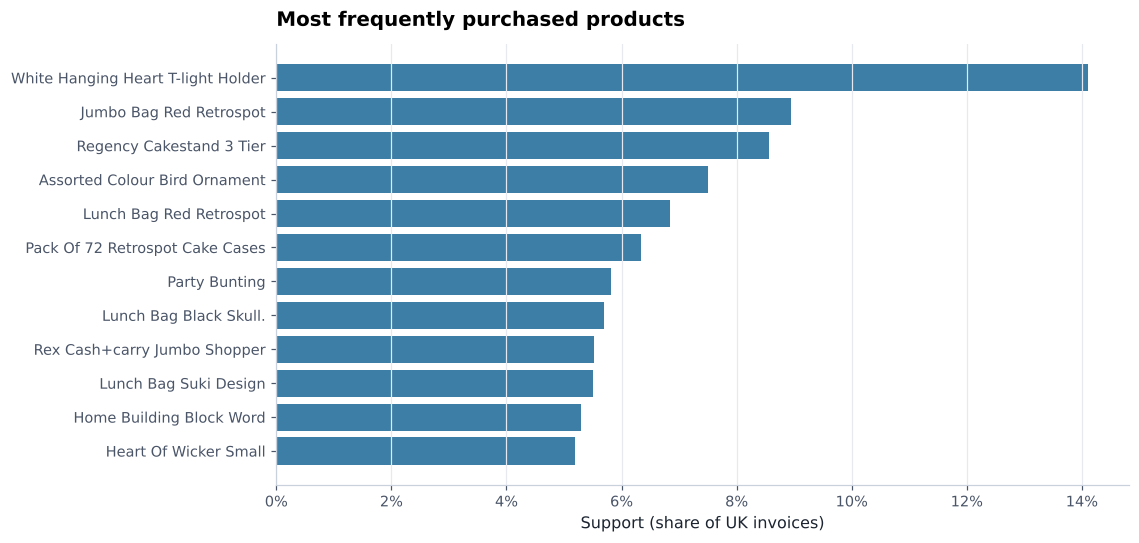

In [8]:
top_single = itemsets_table[itemsets_table["Items"] == 1].head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(top_single["Itemset"].map(strip_codes).map(pretty_label), top_single["Support"], color=PALETTE["secondary"])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Support (share of UK invoices)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Most frequently purchased products")
save_figure(fig, "03_top_item_support")
plt.show()

## 4. Association rules

Rules are kept when **confidence >= 30%** and **lift > 1**.

* **Support**: share of invoices containing both sides of the rule.
* **Confidence**: probability of buying the consequent given the antecedent is in the basket.
* **Lift**: how much more likely the pair is than if purchases were independent (lift 10 = ten times more likely).
* **Conviction**: how strongly the rule would be violated if items were independent; higher is stronger.

In [9]:
rules = generate_rules(itemsets)
rules_table = readable_rules(rules)
print(f"Association rules: {len(rules_table):,}")
print(f"Lift range: {rules_table['Lift'].min():.2f} to {rules_table['Lift'].max():.2f} | "
      f"median confidence: {rules_table['Confidence'].median():.1%}")
display_rules = rules_table.assign(
    Antecedent=rules_table["Antecedent"].map(strip_codes),
    Consequent=rules_table["Consequent"].map(strip_codes),
)
display_rules.head(15).style.format(
    {"Support": "{:.2%}", "Confidence": "{:.1%}", "Lift": "{:.2f}", "Leverage": "{:.4f}", "Conviction": "{:.2f}"}
)

Association rules: 510
Lift range: 2.13 to 56.11 | median confidence: 49.0%


,Antecedent,Consequent,Support,Confidence,Lift,Leverage,Conviction
0,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,1.05%,89.3%,56.11,0.0103,9.21
1,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,1.05%,66.1%,56.11,0.0103,2.92
2,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,1.21%,85.4%,53.64,0.0119,6.73
3,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,1.21%,75.9%,53.64,0.0119,4.09
4,SET/6 RED SPOTTY PAPER PLATES,SET/6 RED SPOTTY PAPER CUPS,1.02%,66.3%,50.53,0.0100,2.93
5,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,1.02%,77.4%,50.53,0.0100,4.36
6,SET/10 PINK SPOTTY PARTY CANDLES,SET/10 BLUE SPOTTY PARTY CANDLES,1.17%,63.9%,44.07,0.0114,2.73
7,SET/10 BLUE SPOTTY PARTY CANDLES,SET/10 PINK SPOTTY PARTY CANDLES,1.17%,80.6%,44.07,0.0114,5.05
8,WOODEN TREE CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,1.01%,80.4%,43.60,0.0098,5.00
9,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN TREE CHRISTMAS SCANDINAVIAN,1.01%,54.6%,43.60,0.0098,2.18


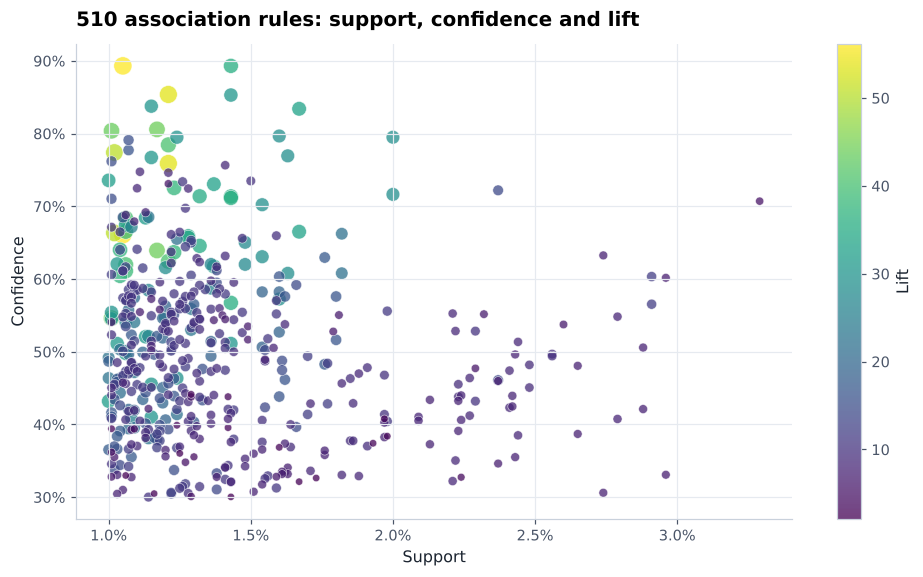

In [10]:
fig, ax = plt.subplots(figsize=(10.5, 5.6))
scatter = ax.scatter(
    rules_table["Support"], rules_table["Confidence"], c=rules_table["Lift"], s=18 + rules_table["Lift"] * 2.2,
    cmap="viridis", alpha=0.75, edgecolors="white", linewidths=0.4,
)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Support")
ax.set_ylabel("Confidence")
ax.grid(axis="x")
ax.set_title(f"{len(rules_table)} association rules: support, confidence and lift")
fig.colorbar(scatter, ax=ax, label="Lift")
save_figure(fig, "03_rules_scatter")
plt.show()

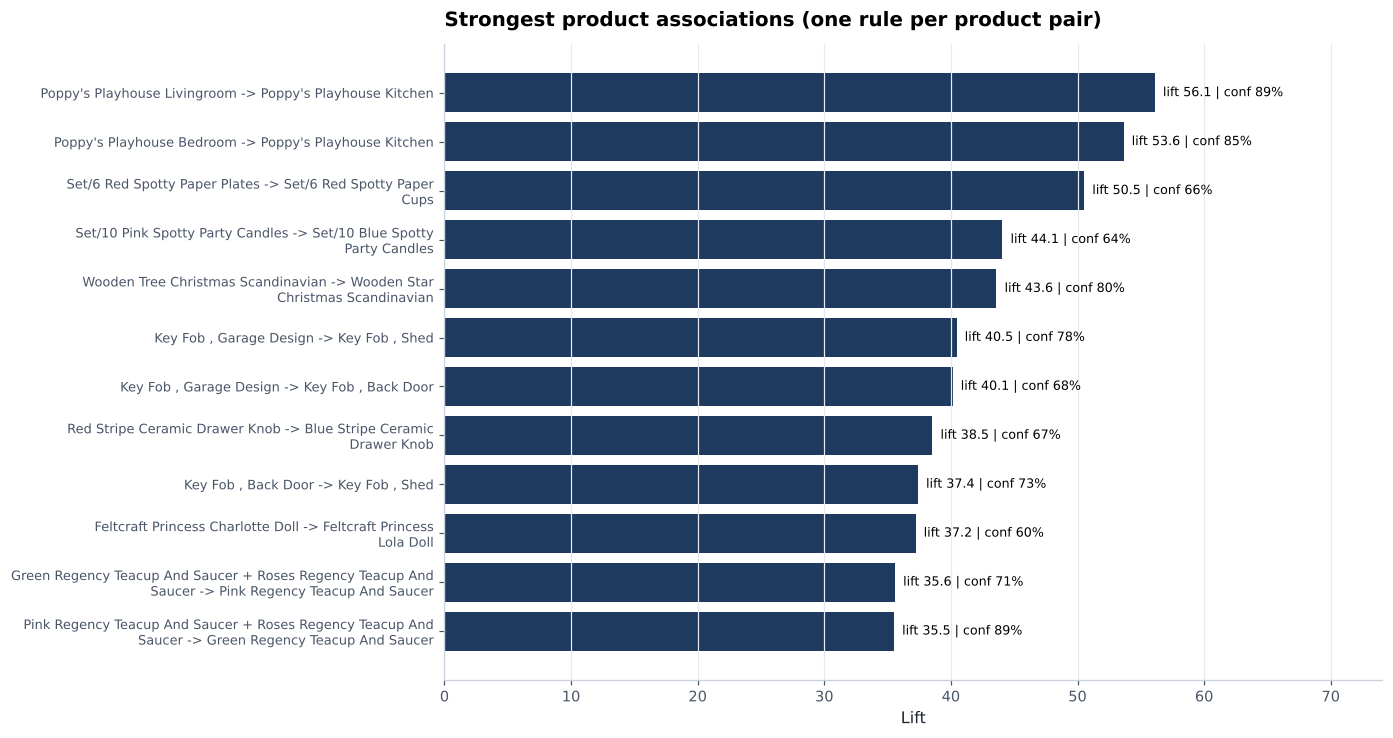

In [11]:
strongest = display_rules.drop_duplicates(subset=["Lift"]).head(12).iloc[::-1]
labels = [
    pretty_label(f"{a}  ->  {c}", width=58)
    for a, c in zip(strongest["Antecedent"], strongest["Consequent"])
]
fig, ax = plt.subplots(figsize=(11, 7.5))
ax.barh(labels, strongest["Lift"], color=PALETTE["primary"])
for y, (lift, conf) in enumerate(zip(strongest["Lift"], strongest["Confidence"])):
    ax.text(lift, y, f"  lift {lift:.1f} | conf {conf:.0%}", va="center", fontsize=8.3)
ax.tick_params(axis="y", labelsize=8.5)
ax.set_xlabel("Lift")
ax.set_xlim(0, strongest["Lift"].max() * 1.32)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Strongest product associations (one rule per product pair)")
save_figure(fig, "03_top_rules_lift")
plt.show()

## 5. Cross-selling recommendations

In [12]:
for i, statement in enumerate(recommendation_statements(rules_table, top_n=10), 1):
    print(f"{i:>2}. {statement}")

 1. Customers who buy POPPY'S PLAYHOUSE LIVINGROOM also buy POPPY'S PLAYHOUSE KITCHEN in 89% of cases (lift 56.1, support 1.05%).
 2. Customers who buy POPPY'S PLAYHOUSE BEDROOM also buy POPPY'S PLAYHOUSE KITCHEN in 85% of cases (lift 53.6, support 1.21%).
 3. Customers who buy SET/6 RED SPOTTY PAPER PLATES also buy SET/6 RED SPOTTY PAPER CUPS in 66% of cases (lift 50.5, support 1.02%).
 4. Customers who buy SET/10 PINK SPOTTY PARTY CANDLES also buy SET/10 BLUE SPOTTY PARTY CANDLES in 64% of cases (lift 44.1, support 1.17%).
 5. Customers who buy WOODEN TREE CHRISTMAS SCANDINAVIAN also buy WOODEN STAR CHRISTMAS SCANDINAVIAN in 80% of cases (lift 43.6, support 1.01%).
 6. Customers who buy KEY FOB , GARAGE DESIGN also buy KEY FOB , SHED in 78% of cases (lift 40.5, support 1.21%).
 7. Customers who buy KEY FOB , GARAGE DESIGN also buy KEY FOB , BACK DOOR in 68% of cases (lift 40.1, support 1.06%).
 8. Customers who buy RED STRIPE CERAMIC DRAWER KNOB also buy BLUE STRIPE CERAMIC DRAWER KN

In [13]:
def anchor_recommendations(product_keyword, n=5):
    mask = display_rules["Antecedent"].str.contains(product_keyword, case=False, regex=False)
    return display_rules[mask].sort_values("Confidence", ascending=False).head(n)[
        ["Antecedent", "Consequent", "Support", "Confidence", "Lift"]
    ].style.format({"Support": "{:.2%}", "Confidence": "{:.1%}", "Lift": "{:.2f}"})

display(Markdown("**Example: what to recommend alongside the best-selling WHITE HANGING HEART T-LIGHT HOLDER**"))
anchor_recommendations("WHITE HANGING HEART")

**Example: what to recommend alongside the best-selling WHITE HANGING HEART T-LIGHT HOLDER**

,Antecedent,Consequent,Support,Confidence,Lift
173,WHITE HANGING HEART T-LIGHT HOLDER + WOODEN PICTURE FRAME WHITE FINISH,WOODEN FRAME ANTIQUE WHITE,1.29%,65.3%,12.67
168,WHITE HANGING HEART T-LIGHT HOLDER + WOODEN FRAME ANTIQUE WHITE,WOODEN PICTURE FRAME WHITE FINISH,1.29%,65.0%,13.46
198,HEART OF WICKER SMALL + WHITE HANGING HEART T-LIGHT HOLDER,HEART OF WICKER LARGE,1.01%,60.6%,11.75
287,HEART OF WICKER LARGE + WHITE HANGING HEART T-LIGHT HOLDER,HEART OF WICKER SMALL,1.01%,52.3%,10.09


The strongest rules link **variants of the same product family** (Poppy's Playhouse rooms, spotty party tableware,
Scandinavian Christmas decorations, key fobs, teacups and saucers in different colours). Customers who buy one design
very often complete the set. This supports three concrete actions: bundle colour or design variants, show "complete
the set" recommendations on product pages and at checkout, and place family members together in catalogues.

# Part B. Customer Segmentation

## 6. RFM feature engineering

The reference date is one day after the last invoice (10 December 2011).

* **Recency**: days since the customer's last purchase (lower is better).
* **Frequency**: number of distinct orders.
* **Monetary**: total spend in GBP.

In [14]:
rfm = compute_rfm(df)
print(f"Customers: {len(rfm):,}")
display(rfm.head())
rfm[RFM_FEATURES].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T

Customers: 5,878


,CustomerID,Recency,Frequency,Monetary,Country
0,12346,325,12,"77,556.46",United Kingdom
1,12347,2,8,"4,921.53",Iceland
2,12348,75,5,"2,019.40",Finland
3,12349,18,4,"4,428.69",Italy
4,12350,310,1,334.40,Norway


,count,mean,std,min,25%,50%,75%,95%,99%,max
Recency,"5,878.00",200.87,209.35,0.00,25.00,95.00,379.00,625.00,726.00,738.00
Frequency,"5,878.00",6.29,13.01,1.00,1.00,3.00,7.00,21.00,46.00,398.00
Monetary,"5,878.00","2,955.90","14,440.85",2.95,342.28,867.74,"2,248.30","9,374.23","29,205.90","580,987.04"


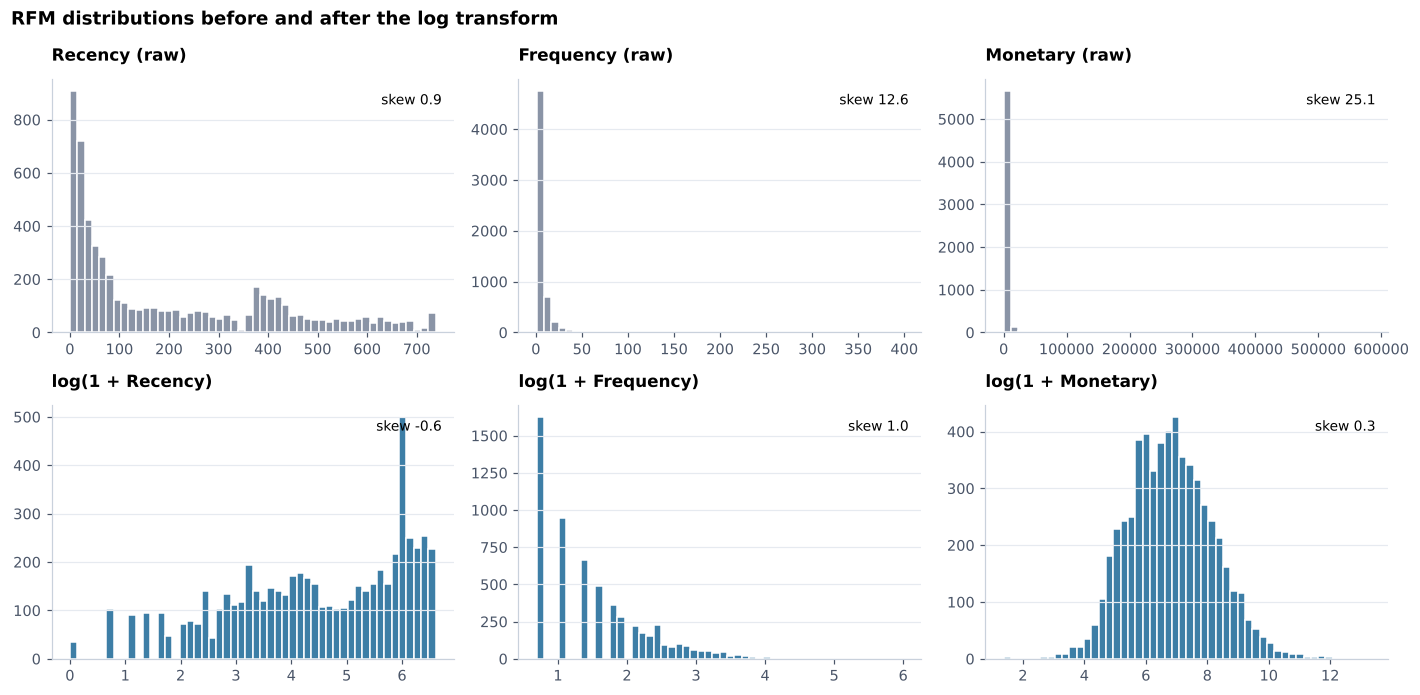

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for col, feature in enumerate(RFM_FEATURES):
    axes[0, col].hist(rfm[feature], bins=50, color=PALETTE["neutral"], edgecolor="white")
    axes[0, col].set_title(f"{feature} (raw)", fontsize=11)
    axes[0, col].text(0.97, 0.9, f"skew {rfm[feature].skew():.1f}", transform=axes[0, col].transAxes, ha="right", fontsize=9)
    transformed = np.log1p(rfm[feature])
    axes[1, col].hist(transformed, bins=50, color=PALETTE["secondary"], edgecolor="white")
    axes[1, col].set_title(f"log(1 + {feature})", fontsize=11)
    axes[1, col].text(0.97, 0.9, f"skew {transformed.skew():.1f}", transform=axes[1, col].transAxes, ha="right", fontsize=9)
fig.suptitle("RFM distributions before and after the log transform", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "03_rfm_distributions")
plt.show()

Frequency and Monetary are extremely right-skewed. K-Means minimises squared Euclidean distance, so on raw values a
handful of very large customers dominate and the algorithm isolates them instead of finding behavioural groups.
Features are therefore **log-transformed and then standardised** before clustering.

## 7. Choosing the number of clusters

Candidate values of k from 2 to 8 are compared with the elbow method (inertia) and three internal validity indices:
silhouette (higher is better), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better).
At least three segments are required for an actionable marketing plan.

In [16]:
k_scores = evaluate_k_range(rfm)
best_k = select_k(k_scores)
display(k_scores.style.format({"Inertia": "{:,.0f}", "Silhouette": "{:.4f}", "DaviesBouldin": "{:.4f}", "CalinskiHarabasz": "{:,.0f}"}))
print(f"Selected k = {best_k} (highest silhouette among k >= {config.KMEANS_MIN_K})")

,k,Inertia,Silhouette,DaviesBouldin,CalinskiHarabasz
0,2,"8,600",0.4390,0.8731,"6,172"
1,3,"6,376",0.3466,1.0366,"5,187"
2,4,"4,964",0.3652,0.9405,"4,998"
3,5,"4,138",0.3390,0.9581,"4,789"
4,6,"3,584",0.3345,0.9625,"4,604"
5,7,"3,213",0.3048,0.9796,"4,392"
6,8,"2,920",0.3068,0.9769,"4,226"


Selected k = 4 (highest silhouette among k >= 3)


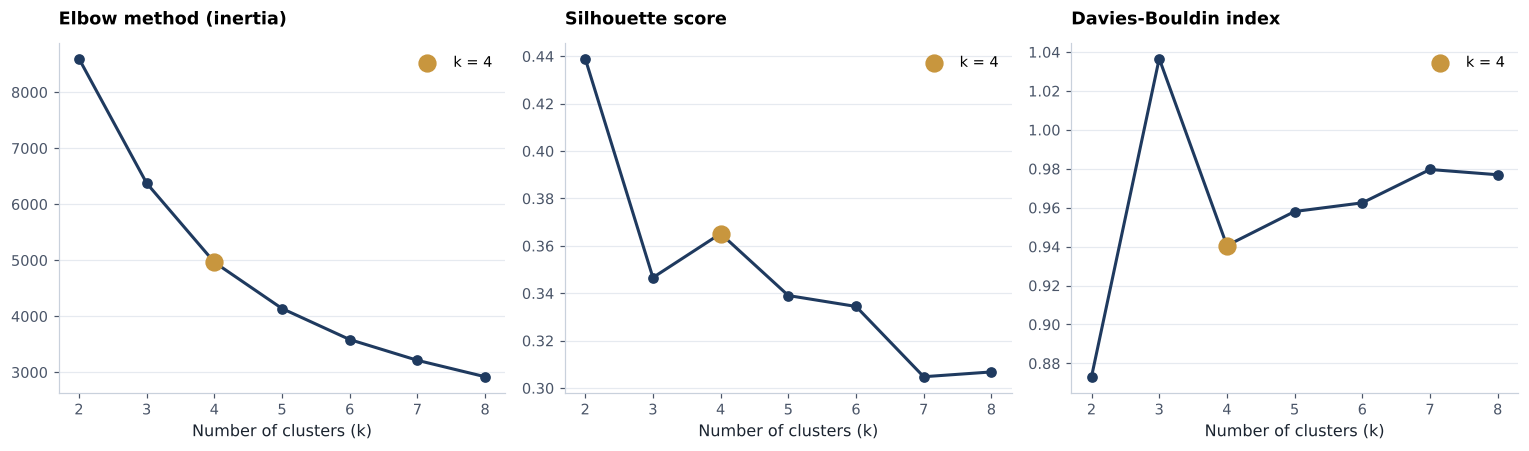

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
metrics = [("Inertia", "Elbow method (inertia)"), ("Silhouette", "Silhouette score"), ("DaviesBouldin", "Davies-Bouldin index")]
for ax, (column, title) in zip(axes, metrics):
    ax.plot(k_scores["k"], k_scores[column], marker="o", color=PALETTE["primary"], linewidth=2)
    selected = k_scores.loc[k_scores["k"] == best_k, column].iloc[0]
    ax.scatter([best_k], [selected], s=120, color=PALETTE["accent"], zorder=3, label=f"k = {best_k}")
    ax.set_title(title, fontsize=11.5)
    ax.set_xlabel("Number of clusters (k)")
    ax.legend(loc="best")
fig.tight_layout()
save_figure(fig, "03_k_selection")
plt.show()

## 8. K-Means segmentation

In [18]:
segments, profile, preprocessor, kmeans = fit_segments(rfm, best_k)
profile

,Segment,Customers,AvgRecency,MedianRecency,AvgFrequency,MedianFrequency,AvgMonetary,MedianMonetary,Revenue,CustomerSharePct,RevenueSharePct
0,Champions,1117,24.80,15.00,20.00,13.00,"11,217.55","5,231.80","12,529,998.21",19.00,72.12
1,Promising,1231,27.86,23.00,3.01,3.00,837.33,720.90,"1,030,747.15",20.94,5.93
2,At Risk,1474,210.60,162.00,5.43,5.00,"2,115.21","1,587.24","3,117,812.45",25.08,17.94
3,Hibernating,2056,393.13,400.00,1.42,1.00,338.64,290.74,"696,246.44",34.98,4.01


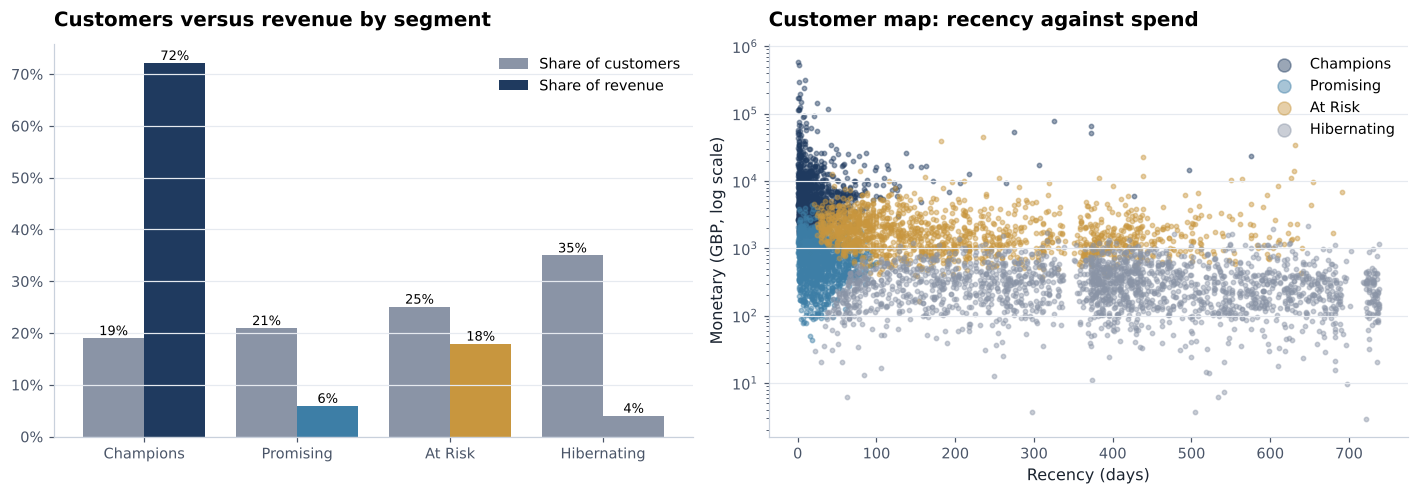

In [19]:
order = list(profile["Segment"])
colors = [config.SEGMENT_COLORS[s] for s in order]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
x = np.arange(len(order))
axes[0].bar(x - 0.2, profile["CustomerSharePct"], width=0.4, color=PALETTE["neutral"], label="Share of customers")
axes[0].bar(x + 0.2, profile["RevenueSharePct"], width=0.4, color=colors, label="Share of revenue")
axes[0].set_xticks(x, order)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
axes[0].set_title("Customers versus revenue by segment")
axes[0].legend()
for i, (c, r) in enumerate(zip(profile["CustomerSharePct"], profile["RevenueSharePct"])):
    axes[0].text(i - 0.2, c, f"{c:.0f}%", ha="center", va="bottom", fontsize=8.5)
    axes[0].text(i + 0.2, r, f"{r:.0f}%", ha="center", va="bottom", fontsize=8.5)

for segment in order:
    subset = segments[segments["Segment"] == segment]
    axes[1].scatter(subset["Recency"], subset["Monetary"], s=8, alpha=0.45, color=config.SEGMENT_COLORS[segment], label=segment)
axes[1].set_yscale("log")
axes[1].set_xlabel("Recency (days)")
axes[1].set_ylabel("Monetary (GBP, log scale)")
axes[1].set_title("Customer map: recency against spend")
axes[1].legend(markerscale=3)
fig.tight_layout()
save_figure(fig, "03_segments_overview")
plt.show()

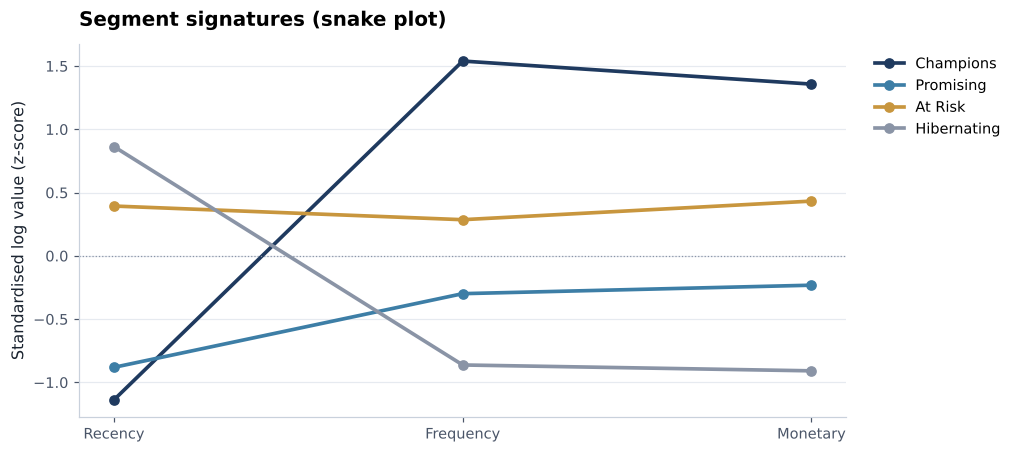

In [20]:
scaled = pd.DataFrame(preprocessor.transform(rfm[RFM_FEATURES]), columns=RFM_FEATURES)
scaled["Segment"] = segments["Segment"].values
snake = scaled.groupby("Segment")[RFM_FEATURES].mean().reindex(order)

fig, ax = plt.subplots(figsize=(9, 4.4))
for segment, row in snake.iterrows():
    ax.plot(RFM_FEATURES, row.values, marker="o", linewidth=2.4, color=config.SEGMENT_COLORS[segment], label=segment)
ax.axhline(0, color=PALETTE["neutral"], linewidth=0.8, linestyle=":")
ax.set_ylabel("Standardised log value (z-score)")
ax.set_title("Segment signatures (snake plot)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure(fig, "03_segment_snake_plot")
plt.show()

In [21]:
segments.groupby("Segment")["Country"].agg(
    Customers="size", UK_Share=lambda s: (s == "United Kingdom").mean()
).reindex(order).style.format({"UK_Share": "{:.1%}"})

,Customers,UK_Share
Segment,,
Champions,1117,90.2%
Promising,1231,90.8%
At Risk,1474,89.6%
Hibernating,2056,92.6%


## 9. Segment playbook

In [22]:
actions = segment_actions(profile)
with pd.option_context("display.max_colwidth", 140):
    display(actions)

,Segment,Customers,RevenueSharePct,Profile,RecommendedAction
0,Champions,1117,72.12,"Recent, frequent and high-spending customers that generate the majority of revenue.","Protect with VIP loyalty tiers, early access to new ranges, dedicated account management and volume-based pricing."
1,Promising,1231,5.93,Recently active customers with few orders so far; the main pipeline for future champions.,"Nurture with onboarding journeys, second-order incentives and cross-sell recommendations driven by the association rules."
2,At Risk,1474,17.94,Previously valuable customers whose last purchase was several months ago.,"Prioritise personalised win-back campaigns, reminders of previously bought items and time-limited offers before they lapse completely."
3,Hibernating,2056,4.01,Low-value customers who bought once or twice and have been inactive for about a year.,Re-engage through low-cost automated email only; exclude from expensive paid campaigns.


In [23]:
for segment in order:
    display(Markdown(f"**{segment}: top customers by spend**"))
    display(segments[segments["Segment"] == segment].nlargest(5, "Monetary")[["CustomerID", "Country", "Recency", "Frequency", "Monetary"]])

**Champions: top customers by spend**

,CustomerID,Country,Recency,Frequency,Monetary
5692,18102,United Kingdom,0,145,"580,987.04"
2277,14646,Netherlands,1,151,"528,602.52"
1789,14156,EIRE,9,156,"313,437.62"
2538,14911,EIRE,1,398,"291,420.81"
5050,17450,United Kingdom,8,51,"244,784.25"


**Promising: top customers by spend**

,CustomerID,Country,Recency,Frequency,Monetary
3,12349,Italy,18,4,"4,428.69"
3403,15782,United Kingdom,9,4,"4,014.10"
2819,15195,United Kingdom,2,1,"3,861.00"
250,12597,Spain,19,4,"3,811.22"
3855,16240,United Kingdom,24,2,"3,718.80"


**At Risk: top customers by spend**

,CustomerID,Country,Recency,Frequency,Monetary
3371,15749,United Kingdom,235,3,"44,534.30"
2722,15098,United Kingdom,182,3,"39,916.50"
1538,13902,Denmark,632,5,"34,095.26"
1698,14063,United Kingdom,438,9,"22,710.20"
88,12435,Denmark,79,6,"13,925.93"


**Hibernating: top customers by spend**

,CustomerID,Country,Recency,Frequency,Monetary
4908,17305,United Kingdom,648,1,"2,135.46"
4643,17039,United Kingdom,604,1,"1,954.99"
416,12764,Lebanon,316,1,"1,693.88"
562,12911,United Kingdom,551,1,"1,651.72"
2934,15310,United Kingdom,478,1,"1,634.64"


## 10. Persist stage outputs

In [24]:
persist_association(itemsets_table, rules_table, basket.shape)
persist_segmentation(k_scores, segments, profile, best_k)
print("Saved: artifacts/association/ and artifacts/segmentation/")

Saved: artifacts/association/ and artifacts/segmentation/


## 11. Key findings

**Market basket analysis**

* 33,361 UK invoices and 4,605 products produce 860 frequent itemsets and 510 rules (confidence >= 30%, lift > 1).
* The strongest affinities are between members of the same product family, with lifts above 40: a customer buying
  *Poppy's Playhouse Livingroom* also buys *Poppy's Playhouse Kitchen* 89% of the time.
* Recommendation engines, "complete the set" bundles and catalogue placement can monetise these patterns directly.

**Customer segmentation**

* A log-scaled RFM space with **k = 4** gives the best silhouette among actionable solutions.
* **Champions** (19% of customers) generate **72% of revenue**; they average 20 orders and their median recency is 15 days.
* **At Risk** customers (25%) were once valuable (average spend above GBP 2,100) but have not ordered for about seven
  months; they hold 18% of historical revenue and are the priority for win-back campaigns.
* **Promising** customers (21%) are recent but have only placed about three orders; they are the pipeline of
  future Champions.
* **Hibernating** customers (35%) bought once or twice about a year ago and contribute 4% of revenue.

Next: notebook 04 predicts which customers will buy next month and how much they will spend.